### Laboratorium 4, część 1: Detekcja obiektów metodami klasycznymi

#### _Fabuła_
_Aby nauczyć głęboki model do segmentacji_ amodalnej _(tj. odpornej na okluzje między obiektami) konieczne jest skonstruowanie odpowiednio anotowanego zbioru uczącego.
Pozyskanie takich danych w drodze manualnej anotacji jest zbyt kosztowne, dlatego obieramy podejście oparte o generowanie danych syntetycznych.
Dane generowane będą na podstawie zbioru_ modalnego, _tj. zawierającego wyłącznie nieprzysłonięte obiekty.
Obiekty te należy najpierw wysegmentować ze specjalnie przygotowanych obrazów źródłowych, a następnie przeanalizować ich kształty -- ten właśnie krok będzie Twoim zadaniem._

#### Zadania

Twoim celem jest wykonanie detekcji i segmentacji _obiektów zainteresowania_ z podanych obrazów źródłowych.

W **pierwszej kolejności** przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający kolekcję obiektów opisanych (1) prostokątem otaczającym (_bounding box_) - na potrzeby detekcji, oraz (2) maską binarną **lub** konturem (tj. zbiorem koordynat punktów brzegowych).
Potok przetwarzania powinien obejmować binaryzację obrazu kolorowego (znanymi Ci już metodami), detekcję komponentów spójności ([`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0)), oraz analizę blobów binarnych (obiektów).
Wykryte obiekty należy przefiltrować tak, aby pozostawić wyłącznie _obiekty zainteresowania_, tj. pojedyncze larwy.
Należy więc usunąć:
* drobne obiekty niebędące larwami,
* instancje złączone,
* wszelkie inne zakłócenia.

Zaimplementuj również funkcję pozwalającą na zaprezentowanie wyników detekcji w formie rysowania prostokątów odpowiadających instancjom oraz segmentacji w formie zaznaczania pikseli należących do instancji (może być w jednej funkcji z opcją wyboru).

**Następnie** opracujesz moduł przetwarzania poszczególnych instancji na poziomie masek binarnych lub konturów.
Moduł ten ma przyjmować pojedynczą instancję i wyznaczać dla niej podstawowe informacje, takie jak:
* długość (skorzystaj z [`skimage.morphology.skeletonize`](https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.skeletonize)) - relatywnie łatwa do _estymacji_, ale dość trudna do precyzyjnego _pomiaru_,
* grubość - może stanowić wyzwanie,
* klasyfikację kształtu (I-kształtne, S-kształtne, C-kształtne) -- potencjalnie trudne zadanie,
* ...

Nie musisz implementować ich wszystkich: na maksymalną ocenę wystarczą dwie miary zrobione _nieźle_ lub jedna opracowana _solidnie_.

#### Oczekiwane rezultaty
1. Zaprojektowanie potoku przetwarzania do detekcji i segmentacji - skonstruuj go najlepiej jako pojedynczą funkcję, ale pozostaw ślad z dokonywanych po drodze eksperymentów, tak aby możliwe było przeanalizowanie przebiegu operacji krok po kroku.
2. Zadbaj o możliwość przetworzenia tylko wybranego RoI z obrazu, aby można było przyjrzeć się "z bliska" wybranym rejonom (np. trudniejszym) -- rekomenduję zacząć pracę od wybrania mniejszego, wygodniejszego w przetwarzaniu rejonu.
3. Działanie modułu analizy zademonstruj na kilku wybranych przykładach, także umożliwiając podgląd operacji krok po kroku.
4. Debugging - jeśli na którymkolwiek etapie pojawią się problemy, których nie potrafisz rozwiązać, postaraj się przynajmniej przeanalizować, co je powoduje.

#### Literatura
1. [`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [OpenCV Structural Analysis and Shape Descriptors](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html), [OpenCV Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html)
2. Publikacja, której częścią był potok przetwarzania podobny do tego, który zaimplementujesz: https://ieeexplore.ieee.org/document/10924163

In [1]:
from collections import Counter
from typing import List

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.morphology as skm
from skimage.graph import MCP_Geometric, pixel_graph
from skimage.segmentation import expand_labels
from scipy.ndimage import gaussian_filter1d, map_coordinates

In [2]:
# staraj się projektować potok przetwarzania na jednym obrazie, a następnie przetestować go na drugim
calib = cv2.imread('Lab4_dane/proc_20221213112112426_image0.jpg')
test = cv2.imread('Lab4_dane/proc_20221213112219030_image0.jpg')
assert calib is not None and test is not None, 'Nie wczytano obrazów - sprawdź ścieżkę'

# Pracuję tylko na dnie pudełka: stały prostokąt (wiersze, kolumny), opis niżej. Pełne obrazy zostają w *_full.
FLOOR = (slice(255, 2730), slice(132, 3970))   # dno pudełka (275:2710, 152:3950) poszerzone o 20 px z każdej strony
calib_full, test_full = calib, test
calib, test = calib_full[FLOOR].copy(), test_full[FLOOR].copy()

### Obszar roboczy: dno pudełka

Obraz tnę od razu po wczytaniu do dna pudełka, czyli stałego prostokąta `FLOOR`. Cały dalszy potok, łącznie z wyborem RoI, pracuje już tylko na tym wycinku. Kamera wisi na stałej wysokości, a pudełko stoi w tym samym miejscu: między `calib` a `test` przesuwa się o ok. 5 px. 

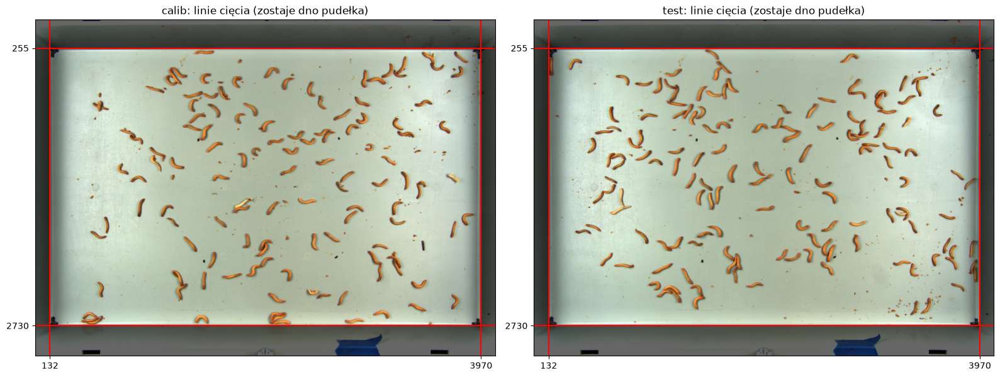

In [3]:
# Linie cięcia na obu obrazach wejściowych: zostaje dno pudełka (prostokąt FLOOR), odcięta część jest przyciemniona
ys, xs = FLOOR
f, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, img, name in zip(axes, (calib_full, test_full), ('calib', 'test')):
    vis = np.ascontiguousarray(img[..., ::-1])
    shown = cv2.convertScaleAbs(vis, alpha=0.4)
    shown[FLOOR] = vis[FLOOR]
    ax.imshow(shown)
    for y in (ys.start, ys.stop):
        ax.axhline(y, color='red', lw=1.5)
    for x in (xs.start, xs.stop):
        ax.axvline(x, color='red', lw=1.5)
    ax.set_xticks([xs.start, xs.stop])
    ax.set_yticks([ys.start, ys.stop])
    ax.set_title(f'{name}: linie cięcia (zostaje dno pudełka)')
plt.tight_layout()

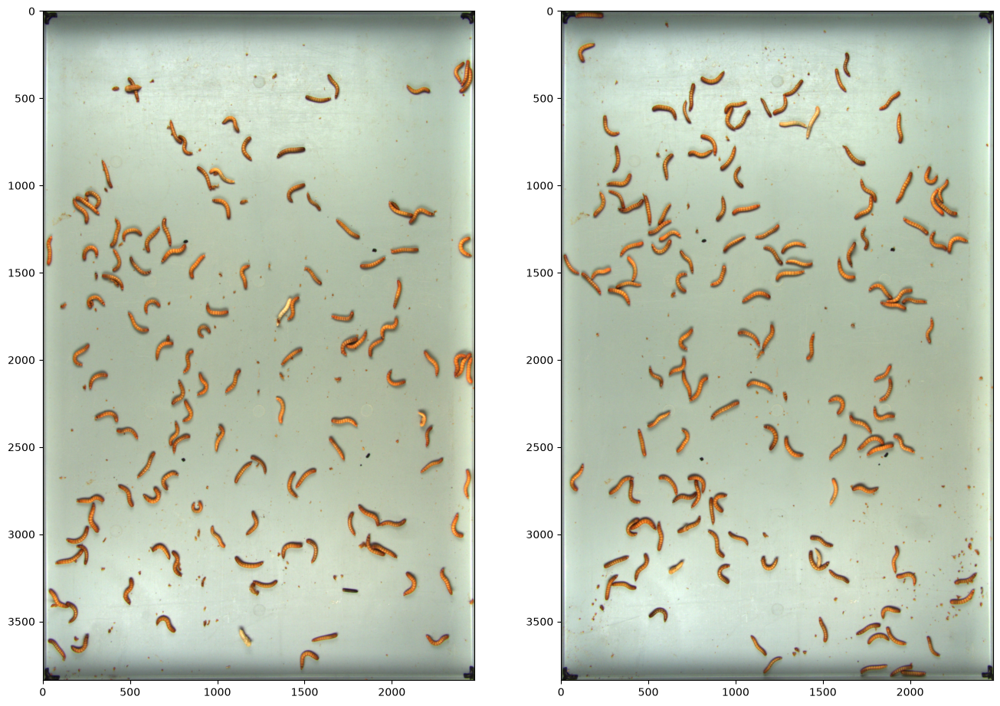

In [4]:
# Obrazy po cięciu: na nich pracuje cały potok (także RoI)
f, (a1, a2) = plt.subplots(1,2,figsize=(16,12))
a1.imshow(calib[...,::-1].transpose((1,0,2)))
a2.imshow(test[...,::-1].transpose((1,0,2)))

### Potok detekcji

Potok odwzorowuje segmentację z artykułu (sekcja III-B2c). `detect_objects` wywołuje kolejno funkcje pięciu kroków, a ich domyślne argumenty to parametry końcowe:

| krok | funkcja | artykuł | parametry końcowe |
|---|---|---|---|
| 1 | `rough_mask` | globalny próg na S | `S_THR` = 104 (Otsu na `calib`) |
| 2 | `find_candidates` | filtr pola, ROI | `min_area` = 1500 px, `margin` = 10 px |
| 3 | `segment_candidate` | lokalny próg z histogramu ROI | `K_GROW` = elipsa 7×7 |
| 4 | `segment_candidate` → `refine_edges` | adaptacyjna erozja (kanał B) | `refine_delta` = 30, `refine_iters` = 4 |
| 5 | `blob_features`, `filter_candidates` | ręczne usunięcie zlepków | `max_extra` = 30 px; `k_len`, `k_width`, `k_area` = 1.35, 1.25, 1.6 |

Krok 6 (`split_clumps`) to dodatkowa analiza poza `detect_objects`: próbuje rozdzielić zlepki odrzucone w kroku 5 na pojedyncze larwy.

Parametry dobierałem iteracyjnie, notatnik pokazuje stan końcowy. Każdy eksperyment zmienia jeden parametr, a pozostałe mają wartości końcowe. Do podglądu służą `show_candidate_steps` (kroki 1–5 dla jednego kandydata) i `display_objects` (prostokąty, maski, odrzuceni kandydaci z powodem).

#### Funkcje pomocnicze

In [5]:
def skeleton_longest_path(skel: np.ndarray):
    """Najdłuższa ścieżka w szkielecie: dwa przebiegi „najdalszego punktu” (dokładne dla drzew).
    Odległości po pikselach szkieletu liczy `skimage.graph.MCP_Geometric` (8-sąsiedztwo: krok prosty 1, ukośny √2).
    Zwraca (długość w px, punkty ścieżki jako tablicę (N, 2) [y, x])."""
    if not skel.any():
        return 0.0, np.empty((0, 2), int)
    cost = np.where(skel, 1.0, np.inf)  # poza szkieletem nie da się przejść

    def farthest(start):
        mcp = MCP_Geometric(cost, fully_connected=True)
        dist, _ = mcp.find_costs([start])
        dist[~np.isfinite(dist)] = -1
        end = np.unravel_index(np.argmax(dist), dist.shape)
        return end, float(dist[end]), mcp

    a, _, _ = farthest(tuple(np.argwhere(skel)[0]))  # od dowolnego punktu do najdalszego końca a
    b, length, mcp = farthest(a)                      # od a do najdalszego końca b: ścieżka a-b
    return length, np.array(mcp.traceback(b))


def skeleton_total_length(skel: np.ndarray) -> float:
    """Suma długości wszystkich gałęzi szkieletu. `skimage.graph.pixel_graph` łączy sąsiednie piksele szkieletu
    (8-sąsiedztwo) krawędziami o wadze równej odległości środków (1 lub √2). Macierz jest symetryczna,
    więc każda krawędź jest liczona dwa razy."""
    graph, _ = pixel_graph(skel, mask=skel, connectivity=2)
    return float(graph.sum() / 2)


def refine_edges(mask: np.ndarray, blue: np.ndarray, delta: float = 30, iters: int = 4) -> np.ndarray:
    """Adaptacyjna erozja brzegu (wg artykułu): piksel brzegowy jest usuwany, jeśli średnia kanału B
    w jego otoczeniu 3x3 jest jaśniejsza od średniej B całego obiektu o więcej niż `delta`.
    Larwy są żółte (mało niebieskiego), więc jasne B na brzegu = piksel mieszany z tłem / poświata."""
    m = mask.copy()
    kernel = np.ones((3, 3), np.uint8)
    blue_blur = cv2.blur(blue, (3, 3)).astype(np.float32)
    for _ in range(iters):
        if not m.any():
            break
        mean_obj = blue_blur[m > 0].mean()
        edge = (m > 0) & (cv2.erode(m, kernel) == 0)
        to_remove = edge & (blue_blur > mean_obj + delta)
        if not to_remove.any():
            break
        m[to_remove] = 0
    return m

In [6]:
K_GROW = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))    # krok 3: poszerzenie konturu wstępnego o ok. 3 px
K_SMOOTH = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))  # krok 5: wygładzenie maski przed szkieletyzacją
FEAT_PAD = 10                                                    # margines tła wokół maski przy liczeniu szkieletu


def rough_mask(image: np.ndarray, s_thr: float):
    """Krok 1: binaryzacja wstępna = próg globalny na kanale S (HSV). Zwraca (S, maska wstępna)."""
    S = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)[..., 1]
    return S, (S > s_thr).astype(np.uint8)


def find_candidates(rough: np.ndarray, min_area: int = 1500, margin: int = 10):
    """Krok 2: komponenty spójności maski wstępnej (findContours), odrzucenie drobnych obiektów (< min_area)
    i prostokątne ROI z marginesem wokół każdego pozostałego.
    Zwraca (kandydaci: lista dict(contour, roi=(x0, y0, x1, y1)), kontury drobnych obiektów)."""
    h_img, w_img = rough.shape
    contours, _ = cv2.findContours(rough, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    seeds, small = [], []
    for c in contours:
        if cv2.contourArea(c) < min_area:
            small.append(c)
            continue
        x, y, w, h = cv2.boundingRect(c)
        roi = (max(x - margin, 0), max(y - margin, 0), min(x + w + margin, w_img), min(y + h + margin, h_img))
        seeds.append(dict(contour=c, roi=roi))
    return seeds, small


def segment_candidate(image: np.ndarray, S: np.ndarray, seed: dict, refine_delta: float = 30,
                      refine_iters: int = 4, keep_steps: bool = False):
    """Kroki 3-4 dla jednego kandydata, w jego ROI:
      3. lokalny próg Otsu na S, ograniczony do konturu wstępnego poszerzonego o ok. 3 px (nie skleja z powrotem
         larw, które rozdzielił próg globalny),
      4. adaptacyjna erozja brzegu na kanale B (refine_edges),
    na koniec największa składowa pokrywająca się z konturem wstępnym (odcina fragmenty sąsiadów, które wpadły
    do prostokąta ROI), z wypełnionymi dziurami.
    Zwraca słownik instancji (bbox, mask, contour, area, ...) albo None, gdy nic nie zostało."""
    x0, y0, x1, y1 = seed['roi']
    seed_mask = np.zeros((y1 - y0, x1 - x0), np.uint8)
    cv2.drawContours(seed_mask, [seed['contour']], -1, 1, -1, offset=(-x0, -y0))

    # 3. lokalny próg Otsu na S, tylko w otoczeniu konturu wstępnego
    s_roi = S[y0:y1, x0:x1]
    local_thr, local = cv2.threshold(s_roi, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    local = local & cv2.dilate(seed_mask, K_GROW)

    # 4. adaptacyjna erozja brzegu na kanale B
    refined = refine_edges(local, image[y0:y1, x0:x1, 0], refine_delta, refine_iters)

    # największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami
    _, lab = cv2.connectedComponents(refined)
    ids = np.unique(lab[(seed_mask > 0) & (lab > 0)])
    if len(ids) == 0:
        return None
    best = max(ids, key=lambda i: np.count_nonzero(lab == i))
    cnts, _ = cv2.findContours((lab == best).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    final = np.zeros_like(seed_mask)
    cv2.drawContours(final, [cnt], -1, 1, -1)

    bx, by, bw, bh = cv2.boundingRect(cnt)
    gx, gy = x0 + bx, y0 + by
    h_img, w_img = S.shape
    cand = dict(bbox=(gx, gy, bw, bh), mask=final[by:by + bh, bx:bx + bw].copy(), contour=cnt + np.array([x0, y0]),
                area=int(final.sum()), local_thr=float(local_thr), roi=seed['roi'],
                touches_border=gx == 0 or gy == 0 or gx + bw >= w_img or gy + bh >= h_img)
    if keep_steps:
        cand['steps'] = dict(S=s_roi, seed=seed_mask, local=local, refined=refined, final=final)
    return cand


def blob_features(mask: np.ndarray) -> dict:
    """Opis blobu na potrzeby filtracji (krok 5), liczony z samej maski instancji:
    szkielet wygładzonej maski -> najdłuższa ścieżka (długość) i nadmiar = suma bocznych gałęzi,
    przybliżona grubość = 2 x transformata odległości na środkowych 60% ścieżki.
    To przybliżone cechy do decyzji „jedna larwa czy nie”; dokładny pomiar robi analyze_instance."""
    m = np.pad(mask, FEAT_PAD)
    skel = skm.skeletonize(cv2.morphologyEx(m, cv2.MORPH_OPEN, K_SMOOTH) > 0)
    length, path = skeleton_longest_path(skel)
    extra = max(0.0, skeleton_total_length(skel) - length)
    dt = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    mid = path[int(0.2 * len(path)):int(0.8 * len(path))]
    width_est = 2 * float(np.median(dt[mid[:, 0], mid[:, 1]])) if len(mid) else 0.0
    return dict(length_px=float(length), skeleton_extra=float(extra), width_est=width_est,
                skeleton_path=path - FEAT_PAD if len(path) else path)


def filter_candidates(cands: List, min_area: int = 1500, max_extra: float = 30.0, k_len: float = 1.35,
                      k_width: float = 1.25, k_area: float = 1.6, ref_area: float = None, ref_len: float = None,
                      ref_width: float = None):
    """Krok 5: nadaje każdemu kandydatowi powód odrzucenia `reason` (None = przyjęty), w kolejności:
    maly, krawedz, szkielet (nadmiar >= max_extra), dlugosc (> k_len x mediana), grubosc (> k_width x mediana),
    pole (> k_area x mediana). Mediany liczone z „czystych” kandydatów (bez rozgałęzień, nie na krawędzi),
    chyba że podano `ref_*` (przydatne dla małych RoI). Nie zmienia wejścia: zwraca (nowa lista, mediany)."""
    clean = [c for c in cands if c['skeleton_extra'] < max_extra and not c['touches_border']]

    def median_of(given, key):
        return given if given is not None or not clean else float(np.median([c[key] for c in clean]))

    refs = dict(ref_area=median_of(ref_area, 'area'), ref_len=median_of(ref_len, 'length_px'),
                ref_width=median_of(ref_width, 'width_est'))
    out = []
    for c in cands:
        reason = None
        if c['area'] < min_area:
            reason = 'maly'
        elif c['touches_border']:
            reason = 'krawedz'
        elif c['skeleton_extra'] >= max_extra:
            reason = 'szkielet'
        elif refs['ref_len'] is not None and c['length_px'] > k_len * refs['ref_len']:
            reason = 'dlugosc'
        elif refs['ref_width'] is not None and c['width_est'] > k_width * refs['ref_width']:
            reason = 'grubosc'
        elif refs['ref_area'] is not None and c['area'] > k_area * refs['ref_area']:
            reason = 'pole'
        out.append({**c, 'reason': reason})
    return out, refs


def detect_objects(image: np.ndarray, s_thr: float, min_area: int = 1500, margin: int = 10,
                   refine_delta: float = 30, refine_iters: int = 4, max_extra: float = 30.0,
                   k_len: float = 1.35, k_width: float = 1.25, k_area: float = 1.6,
                   ref_area: float = None, ref_len: float = None, ref_width: float = None, debug: bool = False):
    """Detekcja i segmentacja pojedynczych larw: kroki 1-5 potoku (wzorowanego na artykule, sekcja III-B2c).
    Domyślne wartości argumentów to parametry końcowe.

    Zwraca listę słowników: bbox (x, y, w, h), mask (maska przycięta do bbox), contour (współrzędne globalne),
    area, length_px, width_est, skeleton_extra, skeleton_path (y, x w układzie maski).
    Z debug=True zwraca (obiekty, info): info zawiera obrazy pośrednie, wszystkich kandydatów z powodem
    odrzucenia i obrazy pośrednie kroków 3-4 dla każdego kandydata (`steps`)."""
    S, rough = rough_mask(image, s_thr)                                                    # krok 1
    seeds, small = find_candidates(rough, min_area, margin)                                # krok 2
    cands = []
    for seed in seeds:
        c = segment_candidate(image, S, seed, refine_delta, refine_iters, keep_steps=debug)  # kroki 3-4
        if c is not None:
            cands.append({**c, **blob_features(c['mask'])})
    cands, refs = filter_candidates(cands, min_area, max_extra, k_len, k_width, k_area,
                                    ref_area, ref_len, ref_width)                          # krok 5

    objects = [c for c in cands if c['reason'] is None]
    if not debug:
        return objects
    info = dict(S=S, rough=rough, small=small, n_small=len(small), candidates=cands,
                rejected=[c for c in cands if c['reason'] is not None], **refs)
    return objects, info

In [7]:
def display_objects(image: np.ndarray, objects: List, mode: str = 'both', rejected: List = None,
                    ax=None, title: str = None, labels: bool = True):
    """Wizualizacja detekcji.
    mode: 'bbox' - prostokąty, 'mask' - piksele instancji (losowy kolor), 'both' - jedno i drugie.
    rejected: opcjonalnie odrzuceni kandydaci (czerwony kontur + powód odrzucenia)."""
    vis = np.ascontiguousarray(image[..., ::-1])
    th = max(1, round(max(image.shape[:2]) / 800))
    rng = np.random.default_rng(0)
    if mode in ('mask', 'both'):
        overlay = vis.copy()
        for obj in objects:
            x, y, w, h = obj['bbox']
            region = overlay[y:y + h, x:x + w]
            region[obj['mask'] > 0] = rng.integers(60, 256, 3)
        vis = cv2.addWeighted(overlay, 0.55, vis, 0.45, 0)
    else:
        vis = vis.copy()
    for i, obj in enumerate(objects):
        x, y, w, h = obj['bbox']
        if mode in ('bbox', 'both'):
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 200, 0), th)
        if labels:
            cv2.putText(vis, str(i), (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * th, (0, 130, 0), th)
    for obj in rejected or []:
        cv2.drawContours(vis, [obj['contour']], -1, (255, 0, 0), th)
        if labels:
            x, y, _, _ = obj['bbox']
            cv2.putText(vis, obj['reason'], (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.5 * th, (220, 0, 0), th)
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 12))
    ax.imshow(vis)
    ax.set_title(title or f'{len(objects)} obiektów' + (f', {len(rejected)} odrzuconych' if rejected else ''))
    ax.axis('off')
    return ax


def show_candidate_steps(image: np.ndarray, cand: dict):
    """Podgląd przetwarzania pojedynczego kandydata, kroki 1-5 (wymaga detect_objects(..., debug=True))."""
    x0, y0, x1, y1 = cand['roi']
    st = cand['steps']
    removed = np.zeros((*st['local'].shape, 3), np.uint8)
    removed[st['refined'] > 0] = (255, 255, 255)
    removed[(st['local'] > 0) & (st['refined'] == 0)] = (255, 0, 255)
    final = np.ascontiguousarray(image[y0:y1, x0:x1, ::-1]).copy()
    cnts, _ = cv2.findContours(st['final'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(final, cnts, -1, (0, 255, 0), 1)
    panels = [
        (image[y0:y1, x0:x1, ::-1], 'RGB (ROI kandydata)'),
        (st['S'], 'kanał S'),
        (st['seed'], '1-2. kontur wstępny'),
        (st['local'], f"3. lokalny Otsu (t={cand['local_thr']:.0f})"),
        (removed, '4. erozja B (magenta = usunięte)'),
        (final, f"5. wynik: {cand['reason'] or 'OK'}"),
    ]
    f, axes = plt.subplots(1, len(panels), figsize=(22, 4))
    for ax, (im, t) in zip(axes, panels):
        ax.imshow(im, cmap='gray')
        ax.set_title(t)
        ax.axis('off')
    path = cand['skeleton_path']
    if len(path):
        bx, by = cand['bbox'][0] - x0, cand['bbox'][1] - y0  # położenie maski instancji w ROI
        axes[-1].plot(path[:, 1] + bx, path[:, 0] + by, 'r-', lw=1.5)
    f.suptitle(f"pole={cand['area']}  długość szkieletu={cand['length_px']:.0f}px  "
               f"nadmiar szkieletu={cand['skeleton_extra']:.1f}px")
    plt.tight_layout()

### Łatwy fragment (RoI)

Zaczynam od fragmentu z kilkunastoma larwami, w większości leżącymi osobno. Na nim pokazuję wynik każdego kroku. RoI jest wycinany z obrazu już przyciętego do dna pudełka.

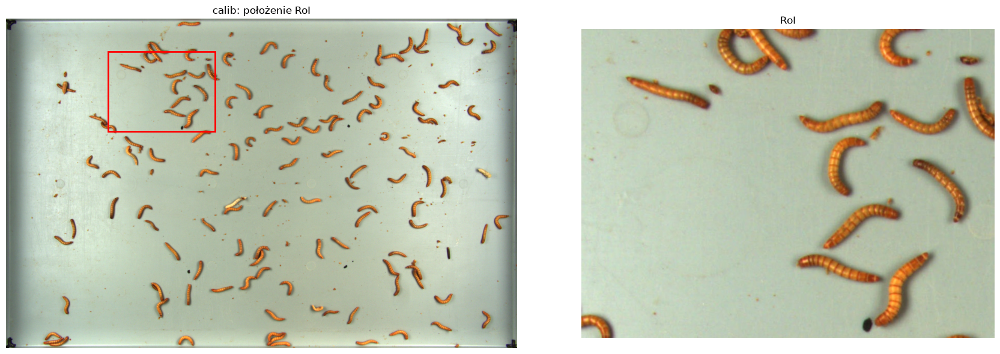

In [8]:
# Łatwy RoI: fragment calib z kilkunastoma larwami, w większości leżącymi osobno (współrzędne w układzie przyciętego obrazu)
roi = (slice(245, 845), slice(768, 1568))
roi_img = calib[roi]

f, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=(1.6, 1)))
a1.imshow(calib[..., ::-1])
a1.add_patch(plt.Rectangle((roi[1].start, roi[0].start), roi[1].stop - roi[1].start, roi[0].stop - roi[0].start,
                           fill=False, color='red', lw=2))
a1.set_title('calib: położenie RoI')
a2.imshow(roi_img[..., ::-1])
a2.set_title('RoI')
for ax in (a1, a2):
    ax.axis('off')
plt.tight_layout()

### Krok 1: binaryzacja wstępna, próg globalny na S (`rough_mask`)

**Binaryzacja wstępna** daje maskę wstępną: przybliżenie, które ma tylko wskazać, gdzie leżą obiekty (kandydaci i ich ROI w kroku 2). Jest szersza niż larwy, bo łapie poświatę, i bywa, że skleja sąsiadów. Ostateczny kształt każdej maski ustalają dopiero lokalny próg (krok 3) i erozja brzegu (krok 4).

Kanały dobieram za artykułem (sekcja III-B2c). Autorzy piszą, że larwy najwyraźniej oddzielają się od tła w **kanale S (nasycenie) modelu HSV** oraz w **kanale B modelu BGR**, i dlatego segmentują w tych dwóch kanałach:
* **S** służy do binaryzacji: najpierw próg globalny (ten krok), potem lokalny w każdym ROI (krok 3).
* **B** służy do doprecyzowania brzegów (adaptacyjna erozja, krok 4).

**Próg globalny na S.** W artykule dobrano go eksperymentalnie. Ja liczę go raz, metodą Otsu na obrazie kalibracyjnym (`S_THR`), i tej samej wartości używam dla RoI i obrazu testowego.

S_THR = 104; powyżej progu: calib 4.7%, test 5.1% pikseli


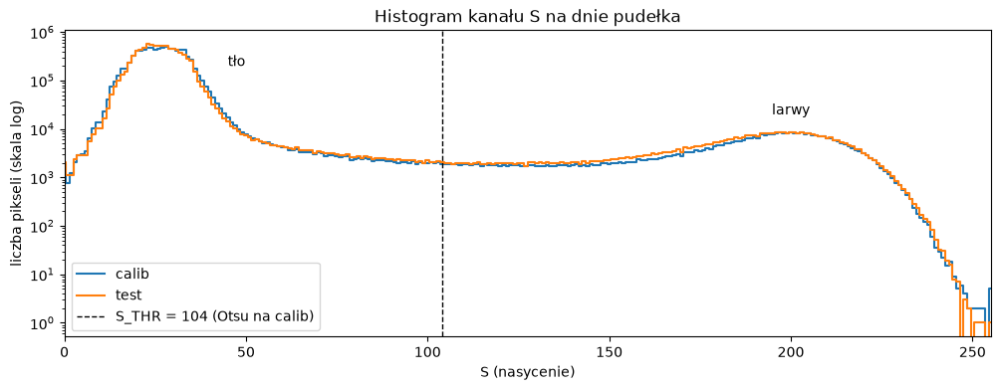

In [9]:
# Próg globalny na S: Otsu liczony raz, na obrazie kalibracyjnym. Ta sama wartość idzie do RoI i obrazu testowego.
S_calib = cv2.cvtColor(calib, cv2.COLOR_BGR2HSV)[..., 1]
S_test = cv2.cvtColor(test, cv2.COLOR_BGR2HSV)[..., 1]
S_THR, _ = cv2.threshold(S_calib, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'S_THR = {S_THR:.0f}; powyżej progu: calib {(S_calib > S_THR).mean():.1%}, test {(S_test > S_THR).mean():.1%} pikseli')

# Histogram S na dnie pudełka; skala log, bo tło to ok. 95% pikseli
f, ax = plt.subplots(figsize=(12, 4))
for S, name in ((S_calib, 'calib'), (S_test, 'test')):
    ax.step(np.arange(256), np.bincount(S.ravel(), minlength=256), where='mid', lw=1.5, label=name)
ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f} (Otsu na calib)')
ax.text(45, 2e5, 'tło', ha='left')
ax.text(200, 2e4, 'larwy', ha='center')
ax.set(yscale='log', xlim=(0, 255), xlabel='S (nasycenie)', ylabel='liczba pikseli (skala log)',
       title='Histogram kanału S na dnie pudełka')
ax.legend()

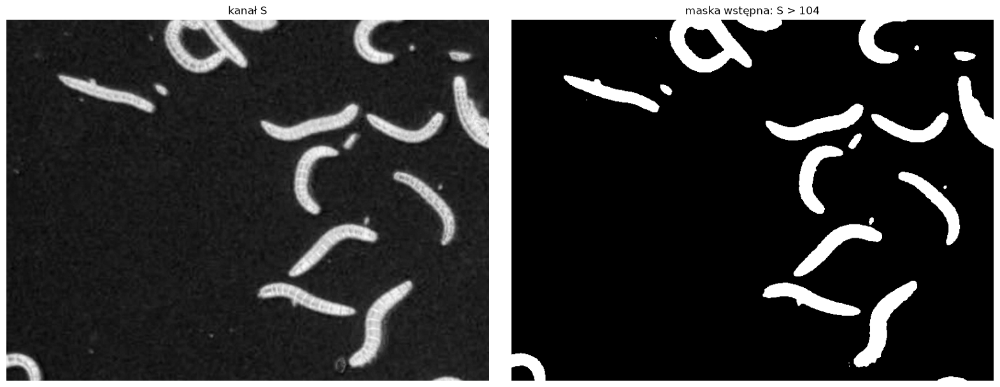

In [10]:
# Krok 1 na RoI: kanał S i maska wstępna
S_roi, rough_roi = rough_mask(roi_img, S_THR)
f, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(S_roi, cmap='gray')
axes[0].set_title('kanał S')
axes[1].imshow(rough_roi, cmap='gray')
axes[1].set_title(f'maska wstępna: S > {S_THR:.0f}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

#### Eksperyment: próg globalny a maska wstępna

Sprawdzam, co próg globalny robi z samą maską wstępną, czyli z wynikiem tego kroku. Liczę tylko kroki 1–2 dla progów 60–160 i śledzę:
* liczbę drobnych obiektów (< `min_area`), czyli szum, który krok 2 musi odrzucić,
* liczbę kandydatów o polu ponad 2× typowa larwa, czyli zlepków już w masce wstępnej,
* medianę pola kandydata, czyli ile poświaty wokół larw wchodzi do maski.

Pod wykresami: maska wstępna przy kilku progach na dwóch trudnych fragmentach `test`.

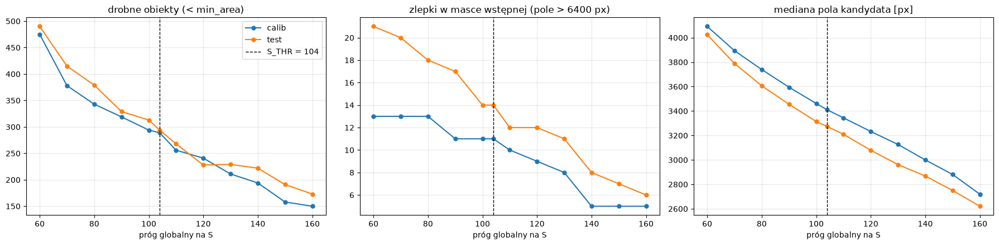

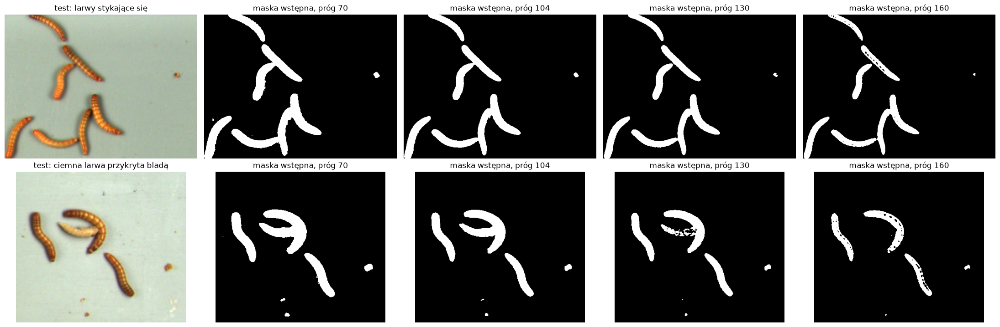

In [11]:
# Eksperyment (krok 1): jak próg globalny zmienia maskę wstępną. Liczone są tylko kroki 1-2, więc to szybkie.
CLUMP_AREA = 2 * 3200  # ok. 2 x mediana pola larwy po segmentacji: większy kandydat to prawie na pewno zlepek
thr_grid = sorted({60, 70, 80, 90, 100, S_THR, 110, 120, 130, 140, 150, 160})
f, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, img in (('calib', calib), ('test', test)):
    stats = []
    for t in thr_grid:
        seeds, small = find_candidates(rough_mask(img, t)[1])
        areas = [cv2.contourArea(s['contour']) for s in seeds]
        stats.append((len(small), sum(a > CLUMP_AREA for a in areas), np.median(areas)))
    for ax, values in zip(axes, zip(*stats)):
        ax.plot(thr_grid, values, 'o-', lw=1.5, ms=5, label=name)
for ax, title in zip(axes, ('drobne obiekty (< min_area)', f'zlepki w masce wstępnej (pole > {CLUMP_AREA} px)',
                            'mediana pola kandydata [px]')):
    ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f}')
    ax.set(title=title, xlabel='próg globalny na S')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()

# Maska wstępna przy kilku progach na dwóch trudnych fragmentach test
zooms = [('larwy stykające się', (slice(20, 470), slice(1320, 1920))),
         ('ciemna larwa przykryta bladą', (slice(1320, 1720), slice(2970, 3420)))]
shown_thr = (70, S_THR, 130, 160)
f, axes = plt.subplots(len(zooms), len(shown_thr) + 1, figsize=(4.4 * (len(shown_thr) + 1), 3.6 * len(zooms)))
for row, (label, zoom) in zip(axes, zooms):
    row[0].imshow(test[zoom][..., ::-1])
    row[0].set_title(f'test: {label}')
    for ax, t in zip(row[1:], shown_thr):
        ax.imshow(rough_mask(test[zoom], t)[1], cmap='gray')
        ax.set_title(f'maska wstępna, próg {t:.0f}')
    for ax in row:
        ax.axis('off')
plt.tight_layout()

**Wniosek (krok 1):**
* **Niski próg (≤ 80)** wpuszcza do maski poświatę wokół larw. Mediana pola kandydata rośnie z ok. 3400 px (przy `S_THR`) do ok. 4100 px (przy 60), drobnych obiektów jest ok. 1.7× więcej, a sąsiednie larwy łączą się przez poświatę w zlepki.
* **Wysoki próg** rozcina zlepki: przy 160 jest ich w masce wstępnej 5 zamiast 11 (`calib`) i 6 zamiast 14 (`test`). Kosztem jest to, że blade larwy rozpadają się na kawałki, a przy 160 maski nawet ciemnych larw mają dziury i przerwy.
* Kandydatów o polu ≥ `min_area` jest prawie tyle samo przy każdym progu (`calib` 102–105, `test` 111–115). Próg globalny nie decyduje więc o tym, *czy* larwa zostanie znaleziona. Decyduje o tym, jak dzielą się zlepki i ile tła wchodzi do maski. Kształt maski i tak ustala później lokalny próg (krok 3).
* Ile z tego zostaje po całym potoku, sprawdzam w sekcji „Wrażliwość wyniku na próg globalny”.

### Krok 2: komponenty spójności i filtr pola (`find_candidates`)

Kontury zewnętrzne maski wstępnej (`cv2.findContours`, `RETR_EXTERNAL`) wyznaczają komponenty spójności. Komponenty o polu `< min_area` to okruchy, odchody i fragmenty wylinek. Odrzucam je od razu, tak jak w artykule („mniejsze niż pojedynczy owad”). Wokół każdego pozostałego komponentu wyznaczam prostokątne ROI z marginesem `margin` = 10 px. W nim działają kroki 3–4.

(np.float64(-0.5), np.float64(799.5), np.float64(599.5), np.float64(-0.5))

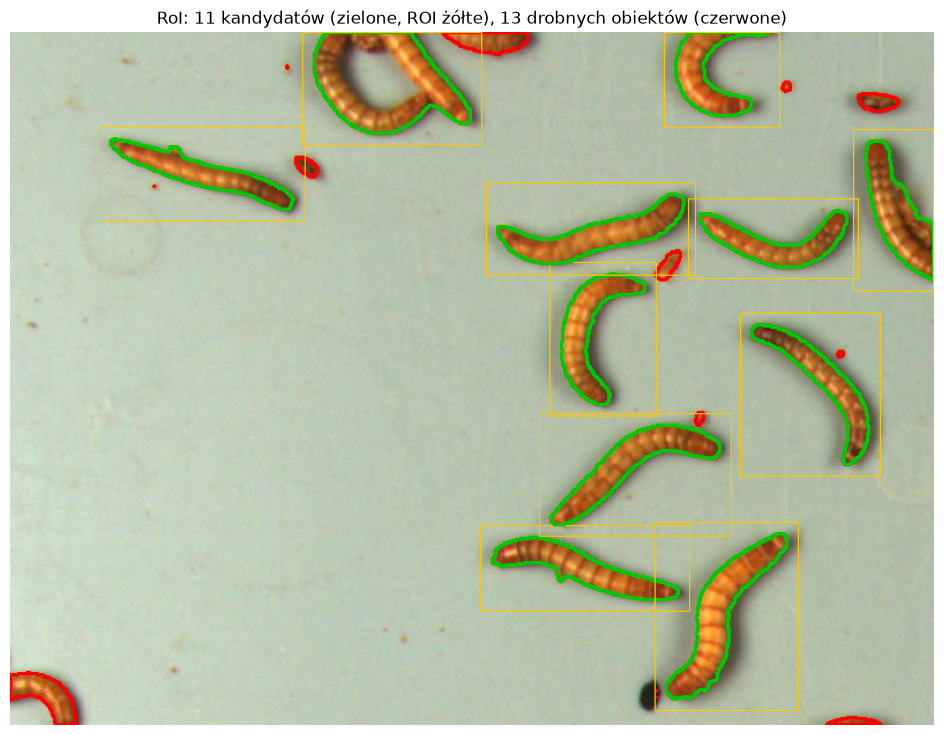

In [12]:
# Krok 2 na RoI: zielone = kandydaci (pole >= min_area) z prostokątem ROI, czerwone = drobne obiekty
seeds_roi, small_roi = find_candidates(rough_roi)
vis = np.ascontiguousarray(roi_img[..., ::-1]).copy()
cv2.drawContours(vis, small_roi, -1, (255, 0, 0), 2)
for s in seeds_roi:
    cv2.drawContours(vis, [s['contour']], -1, (0, 200, 0), 2)
    x0, y0, x1, y1 = s['roi']
    cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), (255, 200, 0), 1)
f, ax = plt.subplots(figsize=(12, 9))
ax.imshow(vis)
ax.set_title(f'RoI: {len(seeds_roi)} kandydatów (zielone, ROI żółte), {len(small_roi)} drobnych obiektów (czerwone)')
ax.axis('off')

calib: komponentów o polu 1000-1700 px: 0, największy drobny: 956 px, najmniejszy kandydat: 1966 px
test: komponentów o polu 1000-1700 px: 0, największy drobny: 821 px, najmniejszy kandydat: 1729 px


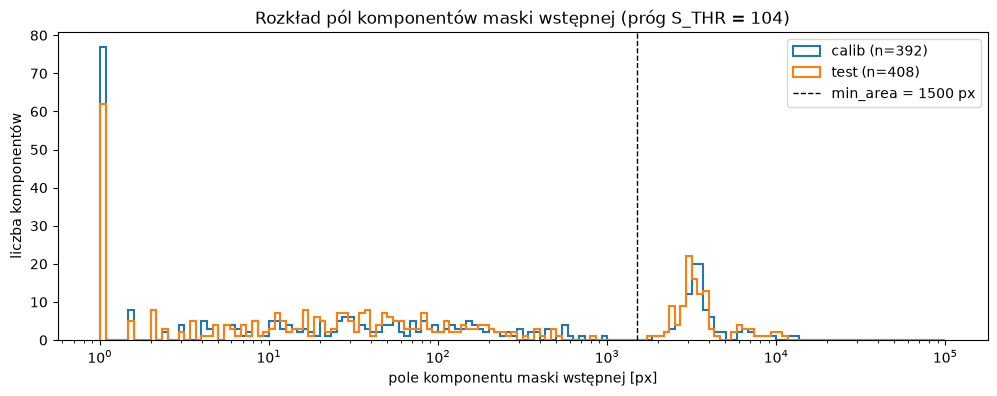

In [13]:
# Uzasadnienie min_area: rozkład pól wszystkich komponentów maski wstępnej (oś x w skali log, 30 przedziałów na dekadę)
bins = np.logspace(0, 5, 151)
f, ax = plt.subplots(figsize=(12, 4))
for name, img in (('calib', calib), ('test', test)):
    cnts, _ = cv2.findContours(rough_mask(img, S_THR)[1], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    areas = np.array([cv2.contourArea(c) for c in cnts])
    ax.hist(np.maximum(areas, 1), bins, histtype='step', lw=1.5, label=f'{name} (n={len(areas)})')
    print(f'{name}: komponentów o polu 1000-1700 px: {np.sum((areas >= 1000) & (areas < 1700))}, '
          f'największy drobny: {areas[areas < 1500].max():.0f} px, najmniejszy kandydat: {areas[areas >= 1500].min():.0f} px')
ax.axvline(1500, color='k', ls='--', lw=1, label='min_area = 1500 px')
ax.set(xscale='log', xlabel='pole komponentu maski wstępnej [px]', ylabel='liczba komponentów',
       title=f'Rozkład pól komponentów maski wstępnej (próg S_THR = {S_THR:.0f})')
ax.legend()

**Wniosek (krok 2):** rozkład pól jest dwumodalny. Drobne obiekty mają najwyżej ok. 960 px, a najmniejszy kandydat ok. 1730 px. Między nimi nie ma na żadnym obrazie ani jednego komponentu. `min_area` = 1500 px leży więc w przerwie i jego dokładna wartość nie ma znaczenia. Pojedyncze larwy mają po segmentacji ok. 1800–4300 px. Na RoI czerwone są też fragmenty larw przeciętych brzegiem RoI, bo ich część wewnątrz RoI ma mniej niż `min_area`.

### Kroki 3–4: segmentacja w ROI (`segment_candidate`)

Dla każdego kandydata, w jego ROI:
* **krok 3:** lokalny próg Otsu na S. Histogram ROI zawiera głównie jedną larwę i tło wokół niej, więc Otsu wyznacza próg dopasowany do tej larwy. Wynik ograniczam do konturu wstępnego poszerzonego o ok. 3 px (`K_GROW`), żeby lokalny próg nie skleił z powrotem larw, które rozdzielił próg globalny. Fragmenty sąsiednich larw, które wpadły do prostokąta ROI, odpadają na końcu, bo zostaje tylko składowa nakładająca się na kontur wstępny.
* **krok 4:** adaptacyjna erozja brzegu na kanale B (`refine_edges`). Larwy są żółto-brązowe, czyli mają mało niebieskiego, więc piksel brzegowy z jasnym B to piksel mieszany z tłem albo poświata. Usuwam go, gdy średnia B w jego otoczeniu 3×3 przekracza średnią B obiektu o więcej niż `delta`.
* Na koniec zostaje największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami.

Poniżej trzech kandydatów z RoI krok po kroku.

lokalne progi Otsu w RoI: [103, 107, 111, 112, 112, 112, 113, 113, 114, 114, 115] (globalny S_THR = 104)


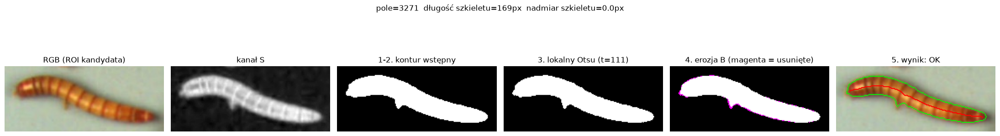

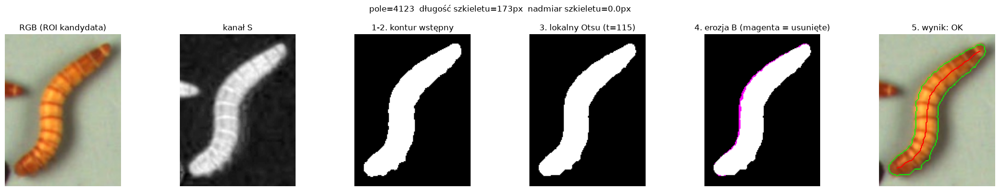

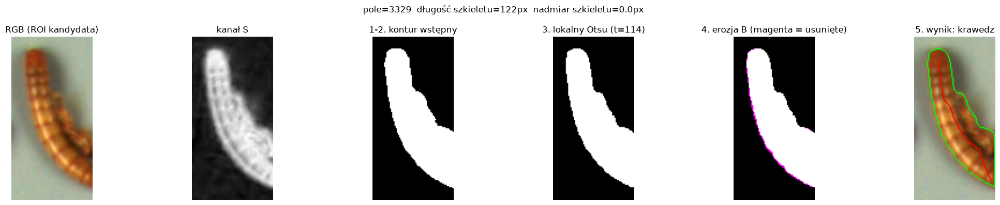

In [14]:
# Kroki 3-4 na RoI: detect_objects z debug=True zapisuje obrazy pośrednie każdego kandydata
objs_roi, dbg_roi = detect_objects(roi_img, S_THR, debug=True)
print('lokalne progi Otsu w RoI:', sorted(round(c['local_thr']) for c in dbg_roi['candidates']),
      f'(globalny S_THR = {S_THR:.0f})')
shown = [c for c in dbg_roi['candidates'] if c['reason'] is None][:2] + [c for c in dbg_roi['candidates'] if c['reason']][:1]
for cand in shown:
    show_candidate_steps(roi_img, cand)

#### Eksperyment: siła erozji brzegu

Erozję liczę wprost funkcją `refine_edges` na masce z kroku 3, dla kilku wartości `delta` (mniejsza `delta` = mocniejsza erozja). Magenta = piksele zdjęte przez erozję. Pod obrazkami: średni odsetek pikseli zdejmowanych z kandydatów RoI.

delta=45             średnio zdjęto 0.8% pikseli maski z kroku 3 (max 1.8%)
delta=30 (końcowa)   średnio zdjęto 4.9% pikseli maski z kroku 3 (max 7.0%)
delta=15             średnio zdjęto 15.0% pikseli maski z kroku 3 (max 18.1%)


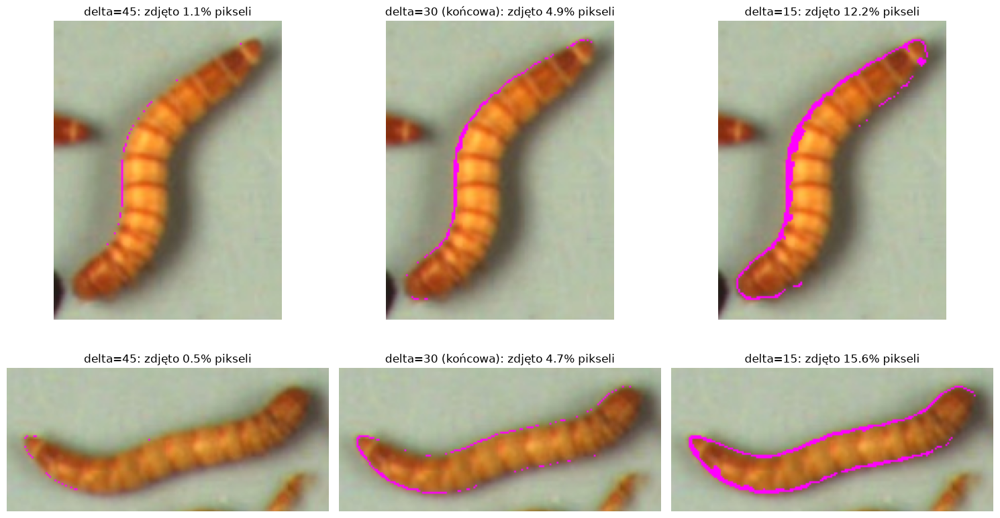

In [15]:
# Eksperyment (krok 4): siła erozji na masce z kroku 3; dalsze kroki nie mają tu znaczenia
deltas = [('delta=45', 45), ('delta=30 (końcowa)', 30), ('delta=15', 15)]


def erosion_effect(cand, delta):
    """Maska z kroku 3 i maska po erozji z daną deltą (układ ROI kandydata)."""
    x0, y0, x1, y1 = cand['roi']
    local = cand['steps']['local']
    return local, refine_edges(local, roi_img[y0:y1, x0:x1, 0], delta)


examples = sorted((c for c in dbg_roi['candidates'] if c['reason'] is None), key=lambda c: -c['area'])[:2]
f, axes = plt.subplots(len(examples), len(deltas), figsize=(5 * len(deltas), 4.5 * len(examples)), squeeze=False)
for row, cand in zip(axes, examples):
    x0, y0, x1, y1 = cand['roi']
    for ax, (name, d) in zip(row, deltas):
        local, eroded = erosion_effect(cand, d)
        vis = np.ascontiguousarray(roi_img[y0:y1, x0:x1, ::-1]).copy()
        vis[(local > 0) & (eroded == 0)] = (255, 0, 255)
        ax.imshow(vis)
        ax.set_title(f'{name}: zdjęto {1 - eroded.sum() / local.sum():.1%} pikseli')
        ax.axis('off')
plt.tight_layout()

for name, d in deltas:
    removed = [1 - e.sum() / l.sum() for l, e in (erosion_effect(c, d) for c in dbg_roi['candidates'])]
    print(f'{name:20s} średnio zdjęto {np.mean(removed):.1%} pikseli maski z kroku 3 (max {np.max(removed):.1%})')

**Wniosek (kroki 3–4):**
* Lokalne progi Otsu w RoI wynoszą 103–115, czyli są równe progowi globalnemu albo trochę wyższe. Krok 3 w praktyce przycina więc maskę wstępną: zdejmuje resztki poświaty i rozcina połączenia dwóch larw przez poświatę (wtedy zostaje tylko największa część). Dlatego wynik końcowy prawie nie zależy od progu globalnego, dopóki ten jest niższy od progów lokalnych (sekcja o wrażliwości wyniku).
* Erozja przy `delta` = 45 zdejmuje pojedyncze piksele (ok. 1% maski). Przy 30 zdejmuje wąski pas jasnych pikseli tam, gdzie brzeg larwy płynnie przechodzi w tło (ok. 5%). Przy 15 zdejmuje szeroki pas wzdłuż całego brzegu i wcina się w ciało larwy (ok. 15%). Wybieram 30. Erozja zmienia głównie brzeg maski, więc najbardziej odczuwa ją pomiar grubości. Sprawdzam to w części o analizie instancji (eksperyment „siła erozji brzegu a pomiar”).

### Krok 5: opis blobu i filtracja (`blob_features`, `filter_candidates`)

Z maski każdego kandydata `blob_features` liczy przybliżone cechy kształtu:
* szkielet wygładzonej maski i jego **najdłuższą ścieżkę**, wyznaczaną dwoma przebiegami „najdalszego punktu” (`skimage.graph.MCP_Geometric`),
* **nadmiar** = całkowita długość szkieletu (`skimage.graph.pixel_graph`) − najdłuższa ścieżka,
* przybliżoną grubość = 2 × transformata odległości na środku ścieżki.

Te cechy służą tylko do decyzji „jedna larwa czy nie”. Dokładny pomiar długości i grubości robi dopiero moduł analizy instancji.

`filter_candidates` odrzuca kandydata z pierwszym pasującym powodem:
* `krawedz`: obiekt dotyka brzegu obrazu (prostokąta `FLOOR`) lub RoI, więc może być ucięty albo wchodzić na ściankę;
* `szkielet`: nadmiar ≥ `max_extra` = 30 px, czyli skrzyżowane albo zlepione larwy;
* `dlugosc`: najdłuższa ścieżka > `k_len` × mediana, czyli larwy stykające się końcami (mają czysty szkielet, ale podwójną długość);
* `grubosc`: grubość > `k_width` × mediana, czyli larwy sklejone bokiem, leżące równolegle (szkielet też mają czysty);
* `pole`: pole > `k_area` × mediana, czyli zabezpieczenie na zlepki, których nie złapały poprzednie reguły.

Progi `dlugosc`, `grubosc` i `pole` są **względne**: odnoszą się do mediany „czystych” kandydatów (bez rozgałęzień, nie na krawędzi), więc dopasowują się do rozmiaru larw w danej partii. Uzasadnienie `max_extra` i progów względnych jest niżej.

RoI: 8 larw, odrzucono: {'krawedz': 3}
mediany z RoI: pole 3101 px, długość 165 px, grubość 20.6 px


<Axes: title={'center': 'RoI: 8 larw, 3 odrzuconych'}>

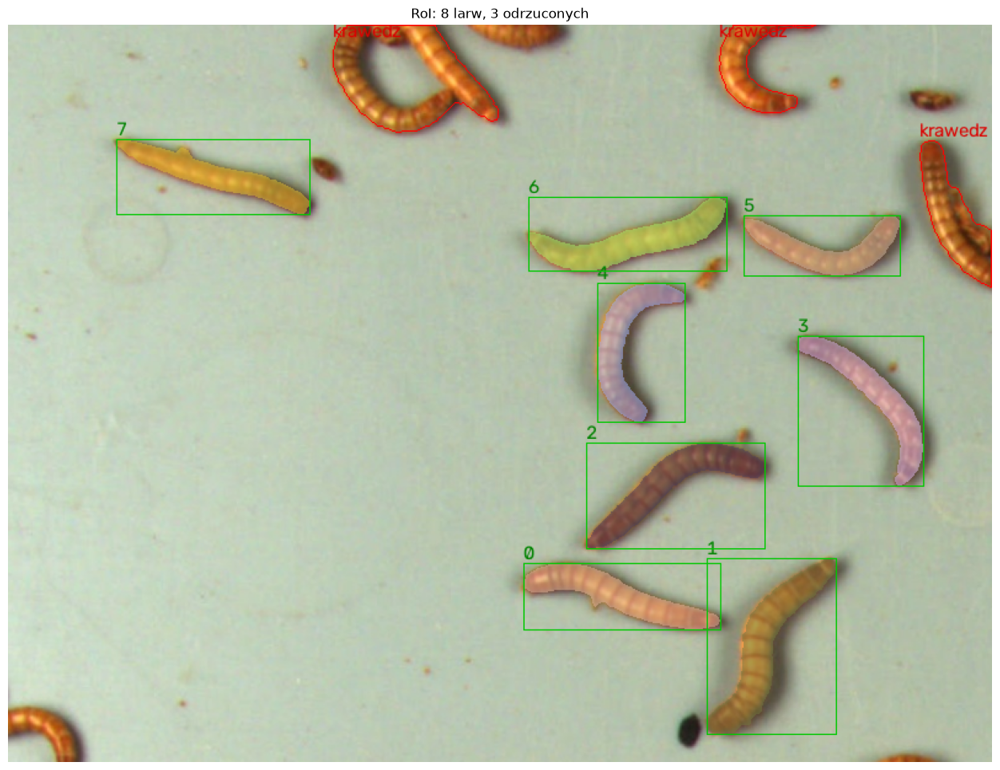

In [16]:
# Krok 5 na RoI: zielone = przyjęte, czerwone = odrzucone z powodem; mediany liczone z samego RoI
print(f"RoI: {len(objs_roi)} larw, odrzucono: {dict(Counter(c['reason'] for c in dbg_roi['rejected']))}")
print(f"mediany z RoI: pole {dbg_roi['ref_area']:.0f} px, długość {dbg_roi['ref_len']:.0f} px, grubość {dbg_roi['ref_width']:.1f} px")
display_objects(roi_img, objs_roi, mode='both', rejected=dbg_roi['rejected'],
                title=f'RoI: {len(objs_roi)} larw, {len(dbg_roi["rejected"])} odrzuconych')

Na RoI nie ma zlepków, więc filtr dobierałem na wszystkich kandydatach z `calib`. `test` służy do sprawdzenia, czy wnioski się przenoszą. Detekcję na obu obrazach liczę tutaj, a wyniki pokazuję w sekcjach „Wynik”.

In [17]:
# Pełna detekcja na obu obrazach (parametry końcowe); eksperymenty z filtrem korzystają z tych kandydatów
objs_calib, dbg_calib = detect_objects(calib, S_THR, debug=True)
objs_test, dbg_test = detect_objects(test, S_THR, debug=True)
print(f'calib: {len(dbg_calib["candidates"])} kandydatów, test: {len(dbg_test["candidates"])} kandydatów')

calib: 103 kandydatów, test: 114 kandydatów


#### Eksperyment: jak powstał filtr zlepków (`max_extra`)

**Pierwsza wersja** uznawała obiekt za pojedynczą larwę, gdy jego szkielet ma dokładnie 2 końce i 0 rozgałęzień. Na całym obrazie ta reguła odrzucała jednak także **poprawne pojedyncze larwy**: drobny okruch przyklejony do brzegu albo nierówność konturu tworzą krótką boczną gałązkę szkieletu.

**Druga próba:** przycinanie krótkich gałązek. Nie pomogło, bo po usunięciu gałązki przy węźle zostawały 1–2-pikselowe resztki, które dalej liczyły się jako końce.

**Wersja końcowa:** zamiast liczyć węzły mierzę **nadmiar**, czyli łączną długość szkieletu poza najdłuższą ścieżką. Krótka wypustka daje mały nadmiar, a druga larwa duży.

Poniżej: rozkład nadmiaru (widać przerwę między pojedynczymi larwami a zlepkami) oraz larwy, które pierwsza reguła by niesłusznie odrzuciła. Na szkielecie żółte punkty to końce, a czerwone gwiazdki to rozgałęzienia.

pierwsza reguła (2 końce, 0 rozgałęzień) odrzuciłaby 9 z 85 larw przyjętych przez wersję końcową


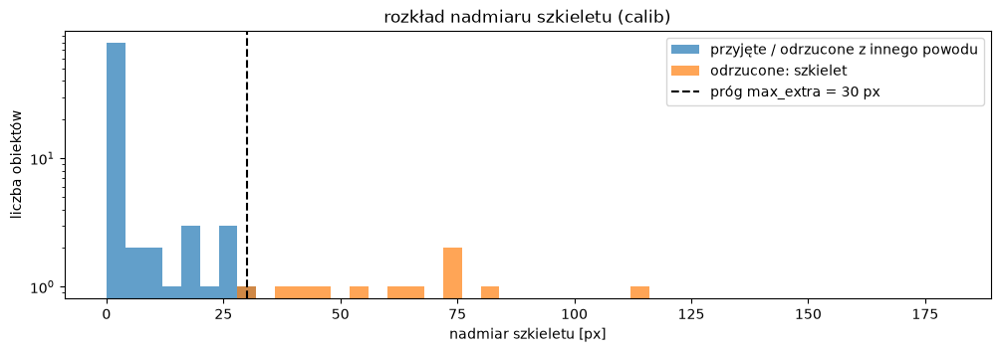

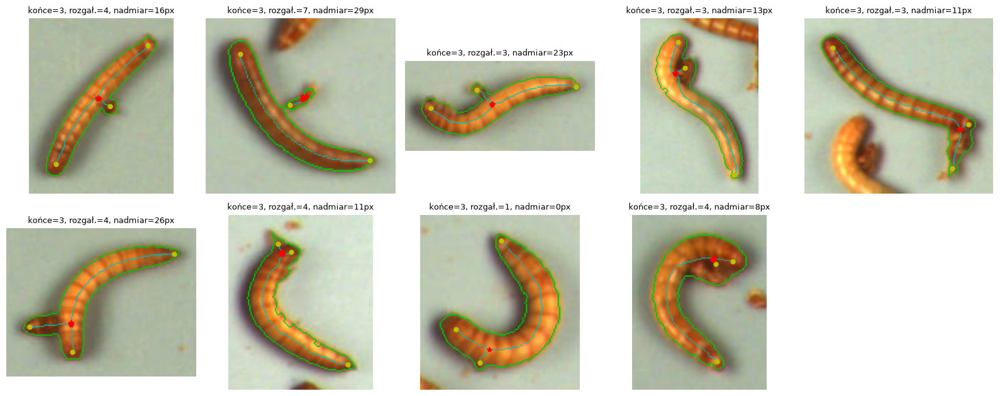

In [18]:
K3 = np.ones((3, 3), np.float32)


def skeleton_nodes(mask: np.ndarray):
    """Szkielet wygładzonej maski oraz jego końce (1 sąsiad) i rozgałęzienia (>= 3 sąsiadów)."""
    sk = skm.skeletonize(cv2.morphologyEx(mask, cv2.MORPH_OPEN,
                                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))) > 0).astype(np.uint8)
    nbrs = (cv2.filter2D(sk, -1, K3, borderType=cv2.BORDER_CONSTANT) - 1) * sk
    return sk, nbrs == 1, nbrs >= 3


def show_gallery(image: np.ndarray, cands: List, title_fn, cols: int = 6, pad: int = 15, draw_skeleton: bool = False):
    """Galeria wycinków z konturem (zielony = przyjęty, czerwony = odrzucony), opcjonalnie ze szkieletem.
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wycinka wybiera pole c['img_name']."""
    if not cands:
        print('(brak obiektów)')
        return
    rows = int(np.ceil(len(cands) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, c in zip(axes.ravel(), cands):
        x, y, w, h = c['bbox']
        x0, y0 = max(x - pad, 0), max(y - pad, 0)
        img = image[c['img_name']] if isinstance(image, dict) else image
        crop = np.ascontiguousarray(img[y0:y + h + pad, x0:x + w + pad, ::-1]).copy()
        cv2.drawContours(crop, [c['contour'] - [x0, y0]], -1, (255, 0, 0) if c.get('reason') else (0, 200, 0), 1)
        ax.imshow(crop)
        if draw_skeleton:
            sk, ends, branches = skeleton_nodes(c['mask'])
            for m_, style, ms in ((sk, 'c.', 1), (ends, 'yo', 5), (branches, 'r*', 6)):
                yy, xx = np.nonzero(m_)
                ax.plot(xx + x - x0, yy + y - y0, style, ms=ms)
        ax.set_title(title_fn(c), fontsize=9)
    plt.tight_layout()


def old_rule_ok(c) -> bool:
    _, ends, branches = skeleton_nodes(c['mask'])
    return ends.sum() == 2 and branches.sum() == 0


cands = [c for c in dbg_calib['candidates'] if not c['touches_border']]
accepted = [c for c in cands if c['reason'] is None]
saved = [c for c in accepted if not old_rule_ok(c)]
print(f'pierwsza reguła (2 końce, 0 rozgałęzień) odrzuciłaby {len(saved)} z {len(accepted)} larw przyjętych przez wersję końcową')

f, ax = plt.subplots(figsize=(12, 3.5))
bins = np.arange(0, 181, 4)
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] != 'szkielet'], bins, alpha=0.7,
        label='przyjęte / odrzucone z innego powodu')
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] == 'szkielet'], bins, alpha=0.7, label='odrzucone: szkielet')
ax.axvline(30, color='k', ls='--', label='próg max_extra = 30 px')
ax.set_yscale('log'); ax.set_xlabel('nadmiar szkieletu [px]'); ax.set_ylabel('liczba obiektów'); ax.legend()
ax.set_title('rozkład nadmiaru szkieletu (calib)')

show_gallery(calib, saved, lambda c: (f"końce={skeleton_nodes(c['mask'])[1].sum()}, "
                                      f"rozgał.={skeleton_nodes(c['mask'])[2].sum()}, nadmiar={c['skeleton_extra']:.0f}px"),
             cols=5, draw_skeleton=True)

#### Uzasadnienie progów względnych (`k_len`, `k_width`, `k_area`)

Dla każdego kandydata, który przeszedł reguły `krawedz` i `szkielet`, liczę stosunek długości, grubości i pola do mediany jego obrazu. Próg względny ma sens, jeśli między pojedynczymi larwami a zlepkami jest przerwa i próg w niej leży. Kolor punktu oznacza ostateczną decyzję filtra. Pod wykresem są przypadki graniczne: najwyższe wartości wśród przyjętych i najniższe ponad progiem, żeby ocenić wzrokowo, co jest pojedynczą larwą.

Czego się spodziewać po budowie zlepka:
* dwie larwy stykające się końcami mają długość ≈ L₁ + L₂, czyli ok. 2× mediana; dla dwóch małych larw mniej, nawet ok. 1.2–1.4×;
* dwie larwy leżące równolegle mogą mieć w środku nawet 2× grubość, ale zwykle stykają się tylko fragmentem, więc mediana grubości na środku osi rośnie mniej;
* pole zlepka to ok. 2× mediana minus część wspólna.

długość  próg 1.35: przyjęte do 1.27 (95. percentyl 1.14); ponad progiem 10 kandydatów, od 1.47; reguła zadziałała jako pierwsza 10 razy
grubość  próg 1.25: przyjęte do 1.23 (95. percentyl 1.12); ponad progiem 5 kandydatów, od 1.27; reguła zadziałała jako pierwsza 4 razy
pole     próg 1.6: przyjęte do 1.36 (95. percentyl 1.19); ponad progiem 9 kandydatów, od 1.74; reguła zadziałała jako pierwsza 0 razy


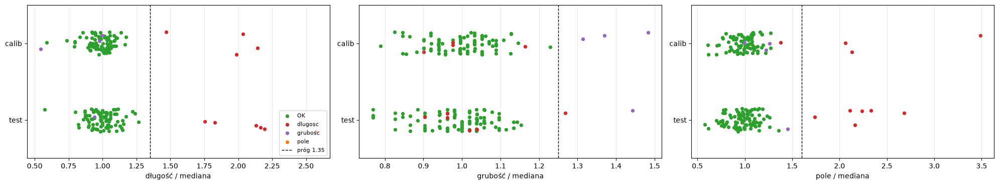

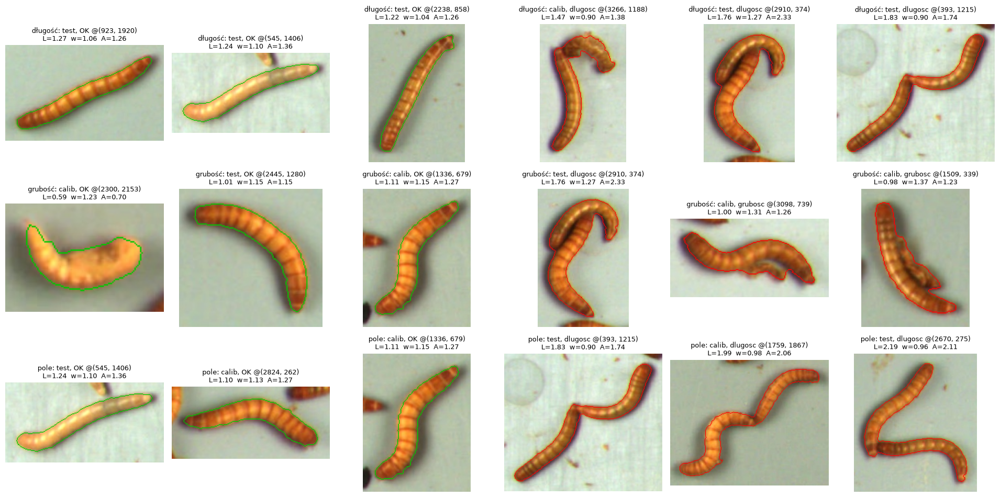

In [19]:
# Stosunek do mediany dla kandydatów, o których decydują progi względne (po regułach krawedz i szkielet)
criteria = [('length_px', 'ref_len', 1.35, 'długość'), ('width_est', 'ref_width', 1.25, 'grubość'),
            ('area', 'ref_area', 1.6, 'pole')]
pool = [dict(c, img_name=name, ratios={key: c[key] / dbg[ref] for key, ref, _, _ in criteria})
        for name, dbg in (('calib', dbg_calib), ('test', dbg_test))
        for c in dbg['candidates'] if c['reason'] not in ('maly', 'krawedz', 'szkielet')]
REASON_COLORS = {'OK': 'tab:green', 'dlugosc': 'tab:red', 'grubosc': 'tab:purple', 'pole': 'tab:orange'}

rng = np.random.default_rng(1)
f, axes = plt.subplots(1, 3, figsize=(20, 3.8))
for ax, (key, _, k, label) in zip(axes, criteria):
    for row, name in enumerate(('test', 'calib')):
        for reason, col in REASON_COLORS.items():
            vals = [c['ratios'][key] for c in pool if c['img_name'] == name and (c['reason'] or 'OK') == reason]
            ax.scatter(vals, row + rng.uniform(-0.15, 0.15, len(vals)), s=18, color=col,
                       label=reason if row == 1 else None)
    ax.axvline(k, color='k', ls='--', lw=1, label=f'próg {k}')
    ax.set(yticks=[0, 1], yticklabels=['test', 'calib'], xlabel=f'{label} / mediana', ylim=(-0.5, 1.5))
    ax.grid(alpha=0.3, axis='x')
axes[0].legend(fontsize=8, loc='lower right')
plt.tight_layout()

for key, _, k, label in criteria:
    ok = [c['ratios'][key] for c in pool if c['reason'] is None]
    above = [c['ratios'][key] for c in pool if c['ratios'][key] > k]
    fired = sum(c['reason'] == {'length_px': 'dlugosc', 'width_est': 'grubosc', 'area': 'pole'}[key] for c in pool)
    print(f'{label:8s} próg {k}: przyjęte do {max(ok):.2f} (95. percentyl {np.percentile(ok, 95):.2f}); '
          f'ponad progiem {len(above)} kandydatów, od {min(above):.2f}; reguła zadziałała jako pierwsza {fired} razy')

# Przypadki graniczne: po 3 najwyższe wśród przyjętych i 3 najniższe ponad progiem, osobno dla każdej cechy
cases = []
for key, _, k, label in criteria:
    ok = sorted((c for c in pool if c['reason'] is None), key=lambda c: -c['ratios'][key])[:3]
    above = sorted((c for c in pool if c['ratios'][key] > k), key=lambda c: c['ratios'][key])[:3]
    cases += [dict(c, crit=label) for c in ok + above]
show_gallery({'calib': calib, 'test': test}, cases, cols=6,
             title_fn=lambda c: (f"{c['crit']}: {c['img_name']}, {c['reason'] or 'OK'} @({c['bbox'][0]}, {c['bbox'][1]})\n"
                                 f"L={c['ratios']['length_px']:.2f}  w={c['ratios']['width_est']:.2f}  "
                                 f"A={c['ratios']['area']:.2f}"))

#### Próg długości: dlaczego 1.35, a nie 1.5

Pierwotnie `k_len` wynosiło 1.5. Wykres pokazuje, ile larw przyjmuje filtr przy różnych wartościach `k_len`, przy pozostałych regułach bez zmian. `filter_candidates` działa na gotowych cechach, więc segmentacji nie trzeba powtarzać. Pod wykresem: kandydat, dla którego progi 1.5 i 1.35 dają różną decyzję.

calib: przy k_len = 1.35 przyjętych 85, przy 1.5: 86; ta sama liczba dla k_len 1.18-1.46
test: przy k_len = 1.35 przyjętych 91, przy 1.5: 91; ta sama liczba dla k_len 1.27-2.30
decyzja zmienia się dla 1 kandydatów


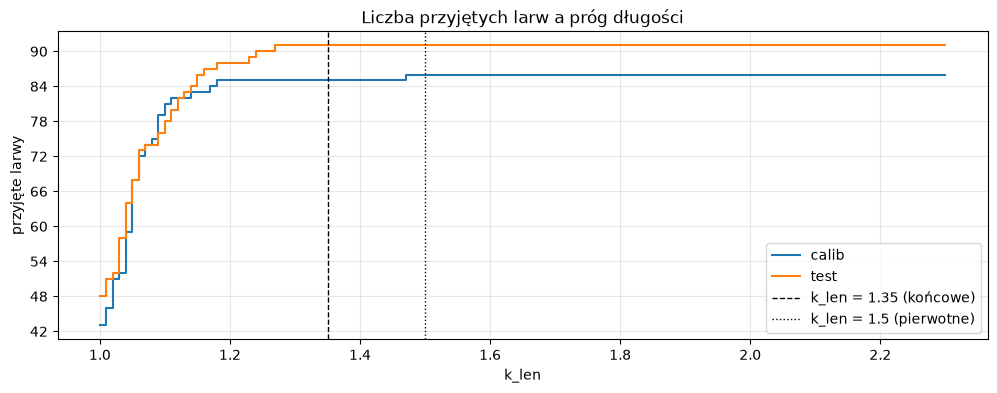

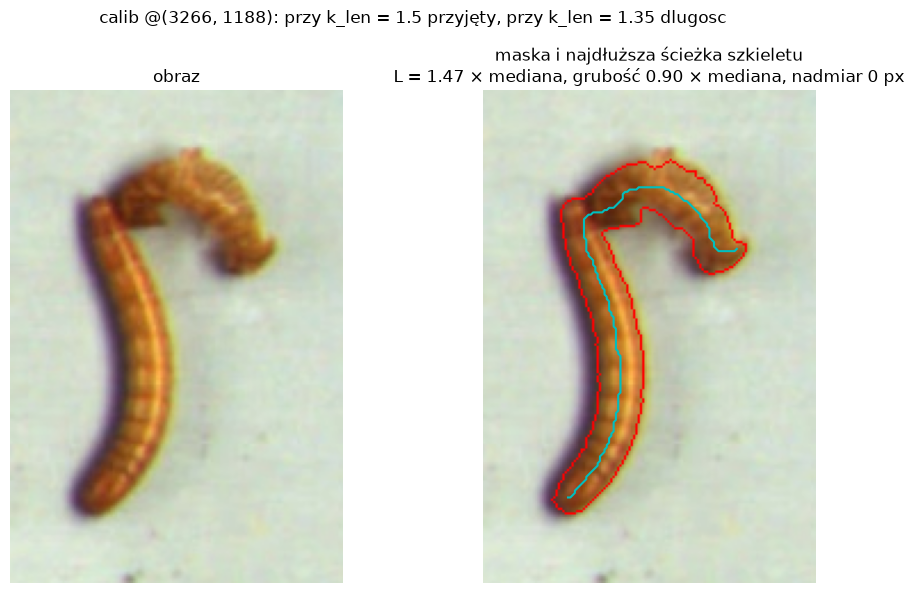

In [20]:
# Liczba przyjętych larw w funkcji k_len (pozostałe reguły bez zmian), na gotowych kandydatach z detekcji
k_grid = np.round(np.arange(1.0, 2.31, 0.01), 2)
f, ax = plt.subplots(figsize=(12, 4))
for name, dbg in (('calib', dbg_calib), ('test', dbg_test)):
    n_ok = [sum(c['reason'] is None for c in filter_candidates(dbg['candidates'], k_len=k)[0]) for k in k_grid]
    ax.step(k_grid, n_ok, where='post', lw=1.5, label=name)
    plateau = k_grid[np.array(n_ok) == n_ok[list(k_grid).index(1.35)]]
    print(f'{name}: przy k_len = 1.35 przyjętych {n_ok[list(k_grid).index(1.35)]}, przy 1.5: {n_ok[list(k_grid).index(1.5)]}; '
          f'ta sama liczba dla k_len {plateau.min():.2f}-{plateau.max():.2f}')
for k, style, label in ((1.35, '--', 'k_len = 1.35 (końcowe)'), (1.5, ':', 'k_len = 1.5 (pierwotne)')):
    ax.axvline(k, color='k', ls=style, lw=1, label=label)
ax.set(xlabel='k_len', ylabel='przyjęte larwy', title='Liczba przyjętych larw a próg długości')
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(alpha=0.3)
ax.legend()

# Kandydaci, dla których k_len = 1.5 i k_len = 1.35 dają różną decyzję
changed = []
for name, img, dbg in (('calib', calib, dbg_calib), ('test', test, dbg_test)):
    at_15, _ = filter_candidates(dbg['candidates'], k_len=1.5)
    at_135, _ = filter_candidates(dbg['candidates'], k_len=1.35)
    changed += [(name, img, dbg, c15, c135) for c15, c135 in zip(at_15, at_135) if c15['reason'] != c135['reason']]
print(f'decyzja zmienia się dla {len(changed)} kandydatów')
for name, img, dbg, c15, c135 in changed:
    x, y, w, h = c135['bbox']
    pad = 30
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    crop = np.ascontiguousarray(img[y0:y + h + pad, x0:x + w + pad, ::-1]).copy()
    f, (a1, a2) = plt.subplots(1, 2, figsize=(10, 6))
    a1.imshow(crop)
    a1.set_title('obraz')
    cv2.drawContours(crop, [c135['contour'] - [x0, y0]], -1, (255, 0, 0), 1)
    a2.imshow(crop)
    path = c135['skeleton_path']
    a2.plot(path[:, 1] + x - x0, path[:, 0] + y - y0, 'c-', lw=1.5)
    a2.set_title(f"maska i najdłuższa ścieżka szkieletu\nL = {c135['length_px'] / dbg['ref_len']:.2f} × mediana, "
                 f"grubość {c135['width_est'] / dbg['ref_width']:.2f} × mediana, nadmiar {c135['skeleton_extra']:.0f} px")
    for ax in (a1, a2):
        ax.axis('off')
    f.suptitle(f"{name} @({x}, {y}): przy k_len = 1.5 {c15['reason'] or 'przyjęty'}, przy k_len = 1.35 {c135['reason'] or 'przyjęty'}")
    plt.tight_layout()

**Wniosek:**
* **Długość (`k_len` = 1.35).** Pojedyncze larwy mają do 1.27× mediany (95. percentyl ok. 1.1×), a zlepki stykające się końcami od 1.47×. Najkrótszy zlepek to obiekt z `calib` @(3266, 1188): **dwie larwy**, prosta i zwinięta, stykające się końcami. Ma czysty szkielet (nadmiar 0), a najdłuższa ścieżka biegnie przez obie larwy. Jest też cieńszy od mediany (0.90×), więc pozostałe reguły go przepuszczają. Pierwotny próg 1.5 leżał tuż nad nim, więc ten zlepek trafiał do wyników jako pojedyncza larwa. Próg 1.35 leży w środku przerwy 1.27–1.47. Dla `k_len` od 1.27 do 1.46 liczba przyjętych larw na obu obrazach się nie zmienia (wykres), więc dokładna wartość w tym zakresie nie ma znaczenia. Granica nie może być ostra: dwie małe larwy (po ok. 0.6×) dają razem tyle, co długa pojedyncza larwa.
* **Grubość (`k_width` = 1.25).** Pojedyncze larwy mają do 1.23× (krótka, skurczona larwa w `calib`), a zlepki od 1.27×. Ten zlepek z `test` i tak odpada przez długość, a zlepki, które łapie tylko grubość, mają od 1.31×. Próg leży w przerwie, ale przerwa jest wąska. Przez grubość odpada też blady, krótki i szeroki obiekt (1.48×, najpewniej poczwarka albo larwa tuż po wylince; widoczny w galerii odrzuconych z `calib` niżej). To nie zlepek, ale też nie typowa larwa. Na `test` przez grubość odpada larwa leżąca przy lewej ściance (1.44×): jej maska obejmuje rozmyty cień na ściance.
* **Pole (`k_area` = 1.6).** Pole nie oddziela pojedynczych larw od zlepków. Duże pojedyncze larwy mają do ok. 1.36× mediany, a dwie larwy sklejone bokiem już od 1.23×, bo częściowo na siebie nachodzą. Na obu obrazach reguła `pole` nie zadziałała ani razu jako pierwsza: każdy kandydat powyżej 1.6× odpada wcześniej przez `szkielet` albo `dlugosc`. Zostawiam ją jako zabezpieczenie. To pokazuje też, dlaczego sam filtr pola, czyli najprostsza alternatywa, by nie wystarczył: myli rozmiar larwy z liczbą larw.
* **Skutek uboczny progów względnych:** reguły `dlugosc` i `grubosc` z definicji obcinają górny ogon rozkładu długości i grubości, który potem mierzę. Na tych obrazach pojedyncze larwy kończą się wyraźnie poniżej progów, więc to nie przeszkadza. W partii o większym rozrzucie rozmiarów te reguły wycięłyby jednak największe osobniki. Reguła `szkielet` nie zależy od rozmiaru i tej wady nie ma.

### Wynik: cały obraz kalibracyjny

Parametry końcowe na całym obrazie. Dochodzą trudniejsze przypadki: skrzyżowane i sklejone larwy, okruchy, odchody i larwy przy ściankach pudełka. Pod spodem jest po jednym przykładzie każdego wyniku (OK i każdy powód odrzucenia), krok po kroku.

calib: 85 larw, odrzucono: {'szkielet': 11, 'dlugosc': 4, 'grubosc': 3}, drobnych obiektów (< min_area): 289
mediana pola = 3238 px, mediana długości szkieletu = 156 px, mediana grubości = 21.3 px


<Axes: title={'center': '85 obiektów, 18 odrzuconych'}>

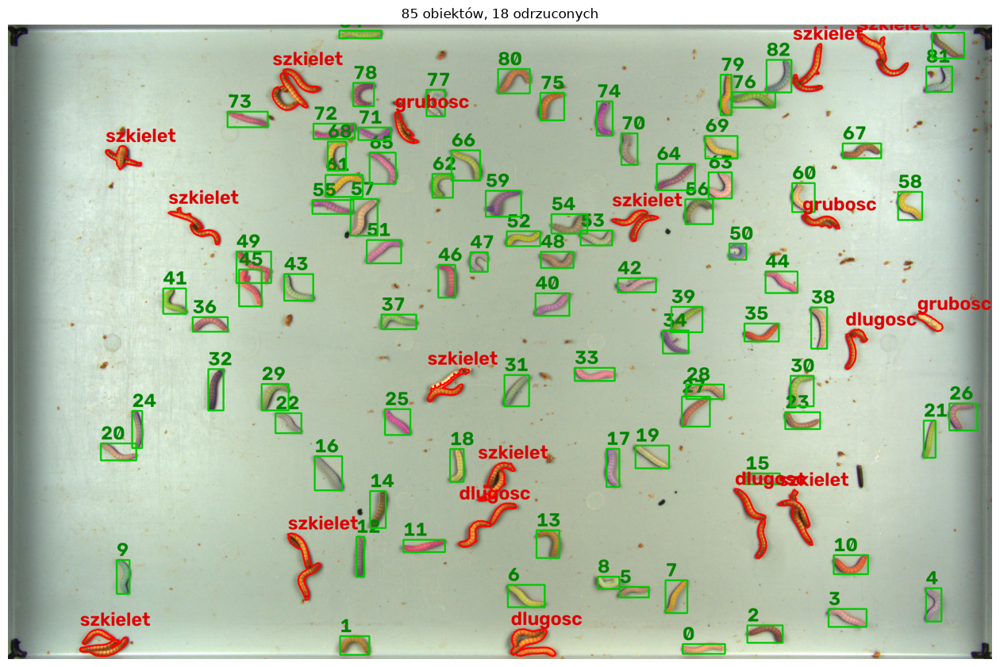

In [21]:
# Cały obraz kalibracyjny (detekcja policzona w kroku 5): zielone = przyjęte larwy, czerwone = odrzuceni kandydaci z powodem
print(f"calib: {len(objs_calib)} larw, odrzucono: {dict(Counter(c['reason'] for c in dbg_calib['rejected']))}, "
      f"drobnych obiektów (< min_area): {dbg_calib['n_small']}")
print(f"mediana pola = {dbg_calib['ref_area']:.0f} px, mediana długości szkieletu = {dbg_calib['ref_len']:.0f} px, "
      f"mediana grubości = {dbg_calib['ref_width']:.1f} px")
display_objects(calib, objs_calib, mode='both', rejected=dbg_calib['rejected'])

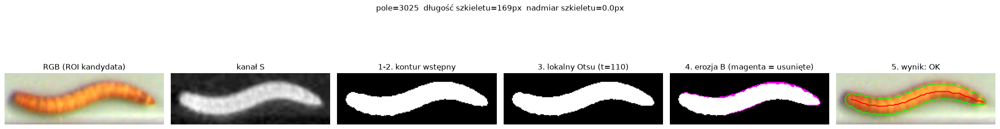

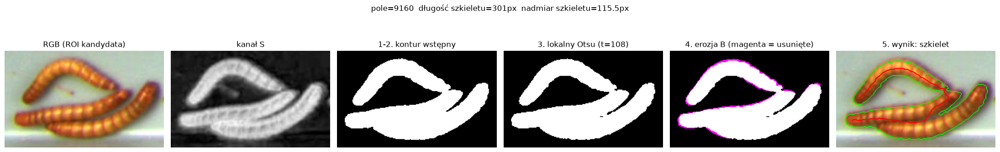

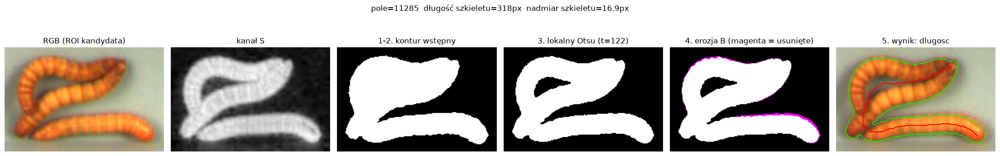

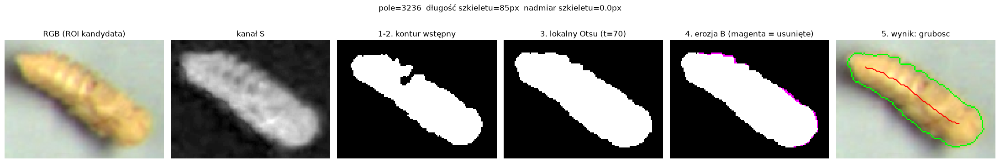

In [22]:
# Pojedyncze obiekty krok po kroku: po jednym przykładzie każdego wyniku (OK + każdy powód odrzucenia)
examples = {}
for c in dbg_calib['candidates']:
    examples.setdefault(c['reason'] or 'OK', c)
for reason, cand in examples.items():
    show_candidate_steps(calib, cand)

#### Dlaczego larwy zostały odrzucone

Wszystkie odrzucone kandydaty z `calib` w powiększeniu, z powodem i wartościami, które o nim zdecydowały. Odniesienia: nadmiar szkieletu < 30 px, długość < 1.35 × mediana, grubość < 1.25 × mediana.

mediany calib: długość 156 px, grubość 21.3 px, pole 3238 px


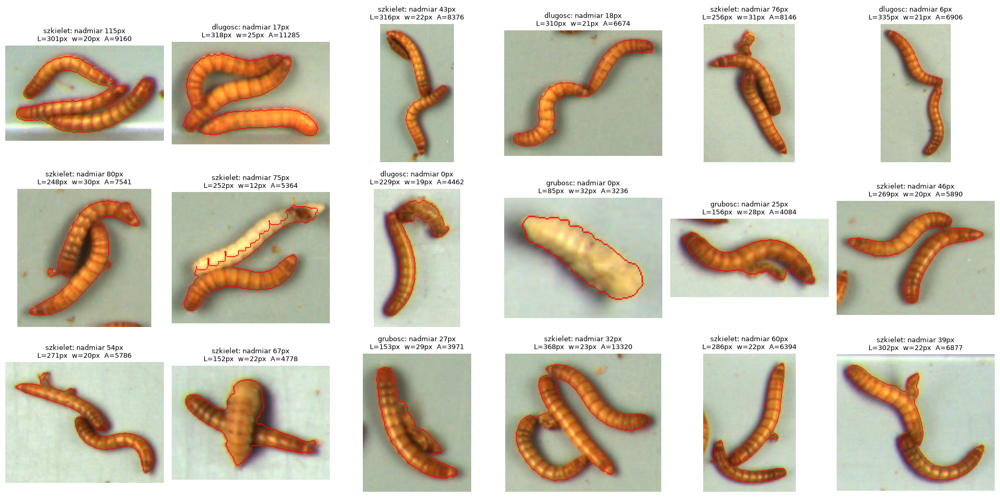

In [23]:
def rejection_title(c) -> str:
    return f"{c['reason']}: nadmiar {c['skeleton_extra']:.0f}px\nL={c['length_px']:.0f}px  w={c['width_est']:.0f}px  A={c['area']}"

print(f"mediany calib: długość {dbg_calib['ref_len']:.0f} px, grubość {dbg_calib['ref_width']:.1f} px, pole {dbg_calib['ref_area']:.0f} px")
show_gallery(calib, dbg_calib['rejected'], rejection_title)

#### Czego w ogóle nie wykrywamy

Odrzuceni kandydaci to nie wszystko. Część obiektów nie przechodzi już przez próg nasycenia (krok 1), więc w ogóle nie staje się kandydatem. Żeby je znaleźć, szukam obiektów wyraźnie innych od tła: ciemniejszych od lokalnej jasności tła albo choć trochę nasyconych, i niepokrytych przez żadnego kandydata. Przy każdym podaję średnie S, które trzeba porównać z progiem `S_THR` = 104.

calib: 9 obiektów spoza kandydatów


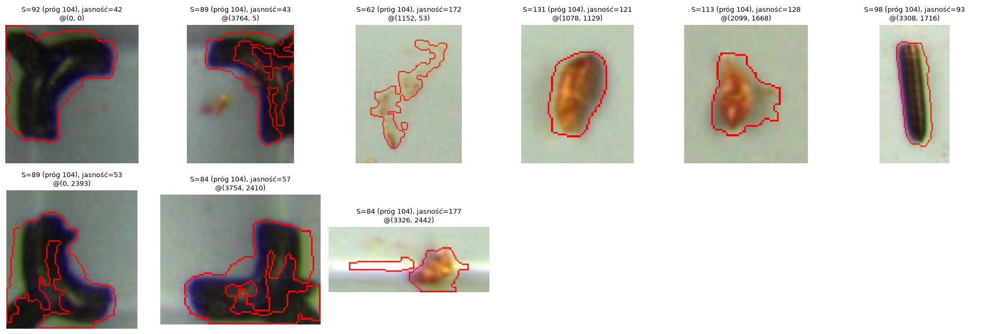

In [24]:
def find_missed(image: np.ndarray, info: dict, min_area: int = 1200, max_area: int = 20000):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    background = cv2.medianBlur(gray, 51)                       # lokalna jasność tła
    anything = ((np.abs(gray.astype(int) - background.astype(int)) > 35) | (hsv[..., 1] > 40)).astype(np.uint8)
    anything = cv2.morphologyEx(anything, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    covered = np.zeros_like(anything)
    for c in info['candidates']:
        cv2.drawContours(covered, [c['contour']], -1, 1, -1)
    covered = cv2.dilate(covered, np.ones((15, 15), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(anything)
    missed = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if not (min_area <= a <= max_area):
            continue
        comp = (lab[y:y + h, x:x + w] == i)
        if covered[y:y + h, x:x + w][comp].mean() >= 0.2:
            continue
        cnts, _ = cv2.findContours(comp.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        missed.append(dict(bbox=(x, y, w, h), contour=max(cnts, key=cv2.contourArea) + [x, y], reason='brak',
                           mean_S=float(hsv[y:y + h, x:x + w, 1][comp].mean()),
                           mean_gray=float(gray[y:y + h, x:x + w][comp].mean())))
    return missed

missed_calib = find_missed(calib, dbg_calib)
print(f'calib: {len(missed_calib)} obiektów spoza kandydatów')
show_gallery(calib, missed_calib, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

### Wynik: obraz testowy

Te same parametry, bez zmian, na drugim obrazie. Progi względne liczone są na nowo z tego obrazu. Pod spodem: odrzuceni kandydaci i obiekty, których nie wykrywamy.

test: 91 larw, odrzucono: {'szkielet': 16, 'dlugosc': 6, 'grubosc': 1}, drobnych: 294
mediana pola: calib 3238 / test 3136,  mediana długości: calib 156 / test 153


<Axes: title={'center': '91 obiektów, 23 odrzuconych'}>

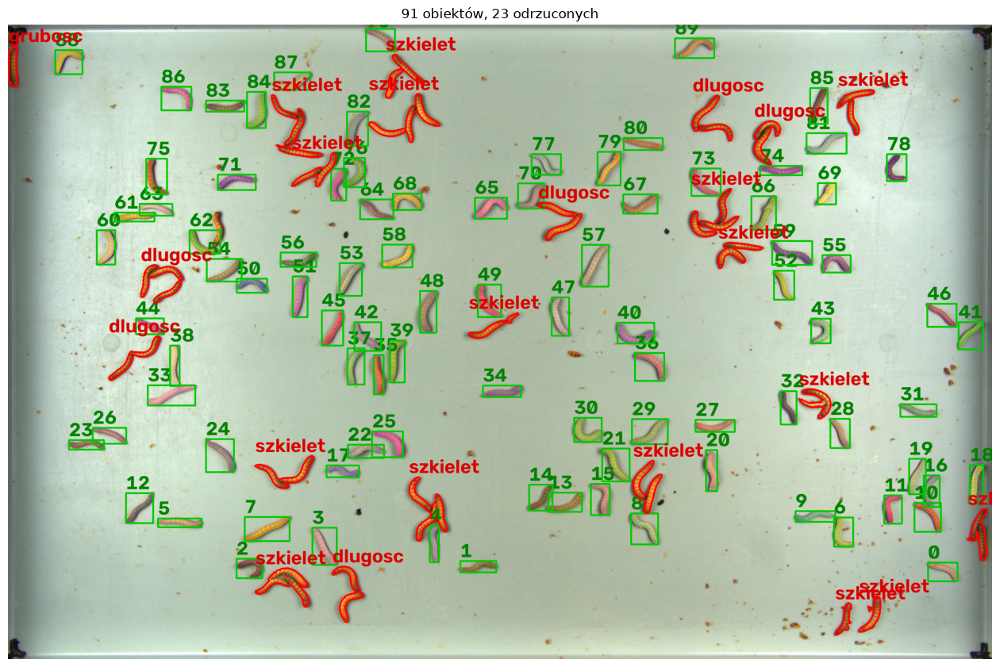

In [25]:
# Obraz testowy (detekcja policzona w kroku 5): te same parametry, także S_THR z calib; progi względne liczone na nowo z tego obrazu
print(f"test: {len(objs_test)} larw, odrzucono: {dict(Counter(c['reason'] for c in dbg_test['rejected']))}, "
      f"drobnych: {dbg_test['n_small']}")
print(f"mediana pola: calib {dbg_calib['ref_area']:.0f} / test {dbg_test['ref_area']:.0f},  "
      f"mediana długości: calib {dbg_calib['ref_len']:.0f} / test {dbg_test['ref_len']:.0f}")
display_objects(test, objs_test, mode='both', rejected=dbg_test['rejected'])

test: 5 obiektów spoza kandydatów


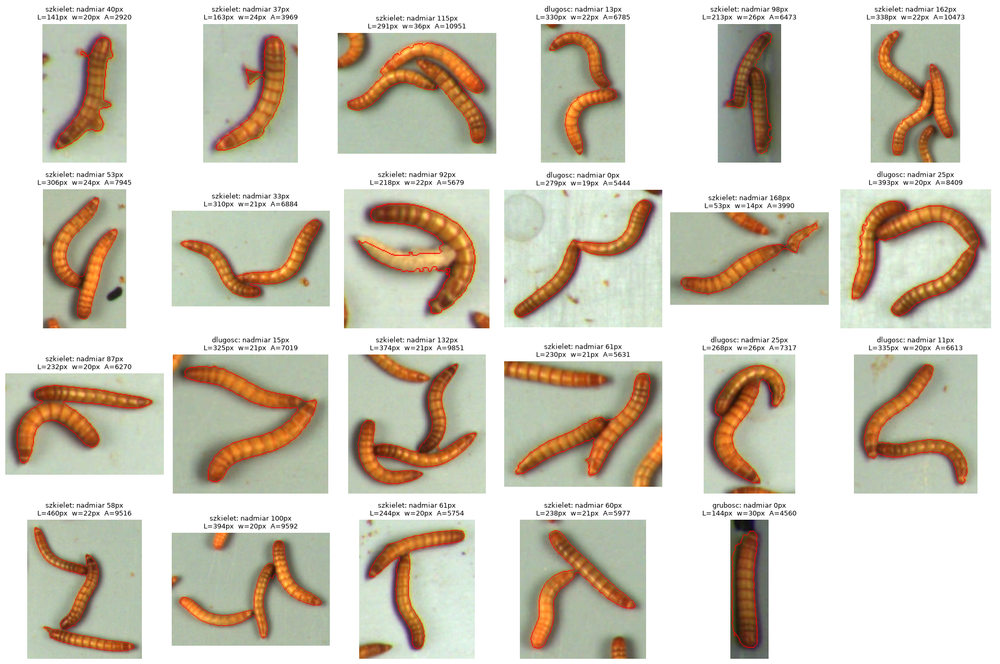

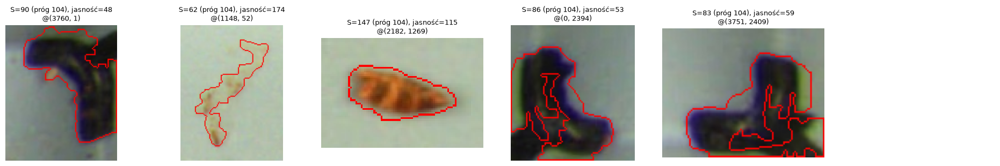

In [26]:
show_gallery(test, dbg_test['rejected'], rejection_title)
missed_test = find_missed(test, dbg_test)
print(f'test: {len(missed_test)} obiektów spoza kandydatów')
show_gallery(test, missed_test, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

#### Wyniki detekcji i dlaczego część larw się zgubiła

| | RoI | calib | test |
|---|---|---|---|
| przyjęte larwy | 8 | 85 | 91 |
| odrzucone `szkielet` (skrzyżowane, zlepione) | – | 11 | 16 |
| odrzucone `dlugosc` (stykające się końcami) | – | 4 | 6 |
| odrzucone `grubosc` (sklejone bokiem, larwa na ściance) | – | 3 | 1 |
| odrzucone `krawedz` (przecięte brzegiem RoI lub `FLOOR`) | 3 | – | – |
| drobne obiekty < 1500 px (okruchy, odchody) | – | 289 | 294 |

Mediany pola i długości są prawie takie same na obu obrazach (3238/3136 px, 156/153 px), więc parametry dobrane na `calib` przenoszą się na `test` bez zmian.

**Odrzuceni kandydaci** (galerie wyżej): prawie wszyscy to rzeczywiście skrzyżowane, stykające się albo zlepione larwy (część z nich rozdziela dodatkowy krok 6). Wyjątki:
* na `test` dwie pojedyncze larwy z przyklejonym okruchem lub fragmentem wylinki (nadmiar szkieletu 37–40 px). Odrzucenie jest ostrożne, ale uzasadnione, bo ich maska i tak byłaby zanieczyszczona. Do budowy bazy instancji lepiej zgubić larwę niż zapisać złą maskę;
* na `test` larwa wspinająca się po lewej ściance, odrzucona przez `grubosc`: jej maska obejmuje rozmyty cień na ściance, więc i tak byłaby za szeroka. Dzięki marginesowi 20 px wokół dna żaden obiekt na `calib` ani `test` nie dotyka brzegu obrazu, więc `krawedz` działa tylko na RoI.

**Obiekty, które w ogóle nie zostały kandydatami** (galerie „czego nie wykrywamy”):
* **narożniki dna pudełka:** czarne elementy w rogach prostokąta `FLOOR` (taśmy i pasków na krawędziach obrazu po przycięciu już nie ma). Pominięte słusznie: są ciemne, a ich fragmenty o S > 104 są mniejsze niż `min_area`;
* **ciemna larwa** (`calib`, ok. (3308, 1716) w układzie przyciętego obrazu): średnie S ≈ 98, czyli tuż pod progiem 104. To prawdziwa strata, bo ciemne, przepoczwarczające się osobniki mają mniej nasycony kolor;
* **krótkie pomarańczowe fragmenty:** S > 104, ale pole poniżej `min_area` = 1500 px. To fragmenty wylinek, główki albo zwinięte małe larwy. Obniżenie `min_area` wpuściłoby też grudki odchodów;
* **jasny, postrzępiony obiekt** o niskim S (≈ 62) przy górnej krawędzi dna, na obu zdjęciach w tym samym miejscu, prawdopodobnie fragment wylinki: słusznie pominięty.

**Inne ograniczenia:**
* jasne larwy (świeżo po wylince) mają niskie S i mogą zostać zgubione albo segmentowane tylko częściowo;
* w jednym przypadku (galeria z eksperymentu z filtrem zlepków, 4. obrazek) przyjęta maska zawiera kawałek ogona sąsiedniej larwy, bo nadmiar szkieletu (13 px) mieści się w progu;
* erozja na kanale B zmienia mierzoną grubość (eksperyment w części analizy). Jej siłę reguluje `refine_delta`.

### Wrażliwość wyniku na próg globalny

Krok 1 pokazał, co próg globalny robi z maską wstępną. Tu sprawdzam, co z tego zostaje po całym potoku. Uruchamiam `detect_objects` dla progów 60–160 przy pozostałych parametrach końcowych i porównuję wynik z wynikiem dla `S_THR`. Larwę uznaję za tę samą, gdy IoU masek ≥ 0.5. „Nowe” to larwy bez pary w wyniku dla `S_THR`, a „zgubione” to larwy z wyniku dla `S_THR` bez pary przy danym progu.

calib
 próg | przyjęte | nowe | zgubione | IoU wspólnych | szkielet | dlugosc | grubosc | krawedz | maly | drobne
   60 |       85 |    0 |        0 |         0.999 |       11 |       4 |       3 |       0 |    2 |    475


   70 |       85 |    0 |        0 |         0.999 |       11 |       4 |       3 |       0 |    1 |    378
   80 |       85 |    0 |        0 |         1.000 |       11 |       4 |       3 |       0 |    1 |    343


   90 |       85 |    0 |        0 |         1.000 |       11 |       4 |       3 |       0 |    0 |    319
  100 |       85 |    0 |        0 |         1.000 |       11 |       4 |       3 |       0 |    0 |    294


  104 |       85 |    0 |        0 |         1.000 |       11 |       4 |       3 |       0 |    0 |    289
  110 |       85 |    0 |        0 |         1.000 |       11 |       4 |       3 |       0 |    0 |    256


  120 |       86 |    1 |        0 |         1.000 |       11 |       4 |       2 |       0 |    0 |    241
  130 |       86 |    1 |        0 |         0.999 |       10 |       4 |       2 |       0 |    0 |    211


  140 |       88 |    3 |        0 |         0.999 |       10 |       4 |       2 |       0 |    0 |    194
  150 |       87 |    3 |        1 |         0.998 |       10 |       4 |       3 |       0 |    0 |    158


... (9 outputs left out)

  130 |       96 |    6 |        1 |         0.997 |       12 |       6 |       1 |       0 |    0 |    229


  140 |       95 |    7 |        3 |         0.999 |       11 |       7 |       1 |       0 |    0 |    222


  150 |       94 |    7 |        4 |         0.998 |       12 |       7 |       1 |       0 |    0 |    191


  160 |       93 |    8 |        6 |         0.996 |       12 |       7 |       0 |       0 |    0 |    173


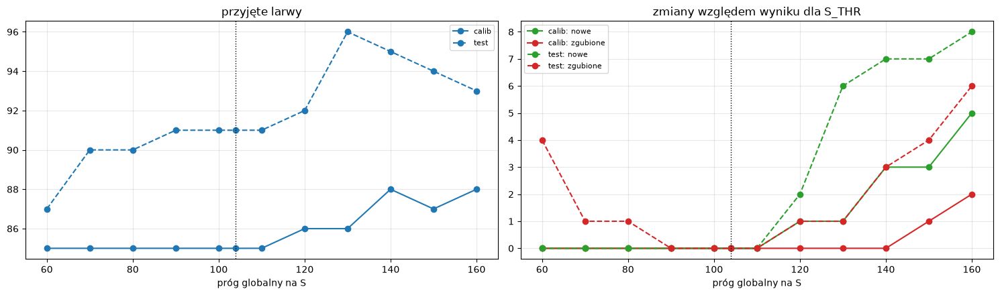

In [27]:
def mask_iou_pairs(objs: List, base: List, shape) -> tuple:
    """IoU każdej larwy z objs z najbardziej pokrywającą się larwą z base.
    Zwraca (tablica IoU dla objs, indeksy larw z base, które nie mają pary z IoU >= 0.5)."""
    lab = np.zeros(shape, np.int32)
    for i, b in enumerate(base, 1):
        x, y, w, h = b['bbox']
        lab[y:y + h, x:x + w][b['mask'] > 0] = i
    ious, paired = [], set()
    for o in objs:
        x, y, w, h = o['bbox']
        under = lab[y:y + h, x:x + w][o['mask'] > 0]
        ids, cnt = np.unique(under[under > 0], return_counts=True)
        iou = 0.0
        if len(ids):
            k = cnt.argmax()
            iou = cnt[k] / (o['area'] + base[ids[k] - 1]['area'] - cnt[k])
            if iou >= 0.5:
                paired.add(ids[k] - 1)
        ious.append(iou)
    return np.array(ious), [i for i in range(len(base)) if i not in paired]


thr_study = {}
for name, img, base in (('calib', calib, objs_calib), ('test', test, objs_test)):
    print(f'{name}\n próg | przyjęte | nowe | zgubione | IoU wspólnych | szkielet | dlugosc | grubosc | krawedz | maly | drobne')
    for t in thr_grid:
        objs, info = detect_objects(img, t, debug=True)
        ious, lost = mask_iou_pairs(objs, base, img.shape[:2])
        same = ious >= 0.5
        r = Counter(c['reason'] for c in info['rejected'])
        thr_study[name, t] = dict(objs=objs, info=info, ious=ious, lost=lost)
        print(f"{t:5.0f} | {len(objs):8d} | {(~same).sum():4d} | {len(lost):8d} | {ious[same].mean():13.3f} | "
              f"{r['szkielet']:8d} | {r['dlugosc']:7d} | {r['grubosc']:7d} | {r['krawedz']:7d} | {r['maly']:4d} | {info['n_small']:6d}")

f, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, ls in (('calib', '-'), ('test', '--')):
    st = [thr_study[name, t] for t in thr_grid]
    axes[0].plot(thr_grid, [len(s['objs']) for s in st], 'o' + ls, color='tab:blue', label=name)
    axes[1].plot(thr_grid, [int((s['ious'] < 0.5).sum()) for s in st], 'o' + ls, color='tab:green', label=f'{name}: nowe')
    axes[1].plot(thr_grid, [len(s['lost']) for s in st], 'o' + ls, color='tab:red', label=f'{name}: zgubione')
for ax, title in zip(axes, ('przyjęte larwy', 'zmiany względem wyniku dla S_THR')):
    ax.axvline(S_THR, color='k', ls=':', lw=1)
    ax.set(title=title, xlabel='próg globalny na S')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()

**Wniosek:**
* **Między 90 a 110 wynik jest identyczny** na obu obrazach: te same larwy, IoU masek ≈ 1.000. `S_THR` = 104 leży w płaskiej dolinie histogramu S, więc przesunięcie progu o kilka jednostek nic nie zmienia. Ostateczny kształt maski ustala lokalny Otsu w kroku 3.
* **Niżej (≤ 80)** na `test` ginie 1–4 larw: poświata skleja je z sąsiadami w jedną składową, z której zostaje tylko największa część. Ciemna larwa z `calib` (S ≈ 98) nie wraca: od progu 80 staje się kandydatem, ale po lokalnym Otsu ma tylko ok. 1280 px, mniej niż `min_area` (kolumna `maly`).
* **Wyżej (≥ 120) przybywa larw**, bo zlepki z maski wstępnej się rozdzielają (maleje liczba odrzuceń `szkielet`). Jednocześnie zaczynają ginąć larwy: na `test` 1 przy 120–130 i 3–6 przy 140–160, bo blade larwy rozpadają się w masce wstępnej na kawałki (krok 1).
* **Decyzja:** zostaję przy `S_THR`. Wyższy próg opłaca się tylko lokalnie, w odrzuconych zlepkach, a nie na całym obrazie. To robi dodatkowy krok 6.

### Krok 6 (dodatkowy): rozdzielanie odrzuconych zlepków (`split_clumps`)

Kroki 1–5 realizują polecenie: zostają tylko pojedyncze larwy, a zlepki odpadają. Ten krok to dodatkowa analiza poza `detect_objects`. Próbuje odzyskać pojedyncze larwy z kandydatów odrzuconych jako zlepki (`szkielet`, `dlugosc`, `grubosc`). Wynik kroków 1–5 i analiza instancji niżej się nie zmieniają.

Pomysł wynika z sekcji o wrażliwości: wyższy próg rozdziela larwy sklejone przez poświatę, ale podniesiony dla całego obrazu gubi blade larwy. Dlatego podnoszę go tylko w obrębie maski zlepka. Dla każdego zlepka `split_clump` sprawdza progi na S co 10 (`thr_step`), od pierwszego powyżej progu lokalnego z kroku 3 do 200. Przy każdym progu:
1. progowanie S w obrębie maski zlepka,
2. otwarcie elipsą 5×5 (`open_k`), które przecina cienkie mostki między larwami,
3. składowe ≥ 500 px (`min_part`) jako znaczniki; mniejsze to okruchy,
4. odbudowa każdego znacznika o 6 px (`grow`) funkcją `skimage.segmentation.expand_labels`, tylko w granicach maski zlepka. Wyższy próg działa jak erozja, a to jest operacja odwrotna: dylatacja, w której piksel trafia do najbliższego znacznika, więc sąsiednie larwy się nie sklejają.

Przyjmuję najniższy próg, przy którym podział jest poprawny:
* zlepek rozpada się na ≥ 2 części i każda przechodzi filtr z kroku 5 (z medianami całego obrazu),
* każda część ma długość ≥ 0.7 × mediana (`k_min`). Krótsza część to najpewniej kawałek larwy przykrytej przez inną,
* części razem pokrywają ≥ 90% maski zlepka (`min_cover`). Inaczej przy tym progu zniknęła cała larwa (np. blada) i jej kawałek mógł się dokleić do sąsiadki.

Jeśli żaden próg nie daje poprawnego podziału, zlepek zostaje odrzucony w całości. Tak jak w całym potoku: lepiej zgubić larwę niż zapisać złą maskę.

In [28]:
CLUMP_REASONS = ('szkielet', 'dlugosc', 'grubosc')


def clump_parts(S: np.ndarray, cand: dict, thr: float, open_k: int = 5, grow: int = 6, min_part: int = 500) -> List:
    """Krok 6 przy jednym progu: podział maski zlepka na części.
    Próg `thr` na S w obrębie maski zlepka -> otwarcie (przecina cienkie mostki między larwami) -> składowe
    >= min_part jako znaczniki -> odbudowa znaczników o `grow` px funkcją expand_labels (dylatacja bez sklejania:
    piksel trafia do najbliższego znacznika), tylko w granicach maski zlepka. Części są opisane jak kandydaci."""
    x, y, w, h = cand['bbox']
    clump = cand['mask'] > 0
    hi = ((S[y:y + h, x:x + w] > thr) & clump).astype(np.uint8)
    if open_k:
        hi = cv2.morphologyEx(hi, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(hi)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_part]
    lab = expand_labels(np.where(np.isin(lab, keep), lab, 0), grow) * clump
    H, W = S.shape
    parts = []
    for i in keep:
        cnts, _ = cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        bx, by, bw, bh = cv2.boundingRect(cnt)
        mask = np.zeros((bh, bw), np.uint8)
        cv2.drawContours(mask, [cnt], -1, 1, -1, offset=(-bx, -by))
        gx, gy = x + bx, y + by
        parts.append(dict(bbox=(gx, gy, bw, bh), mask=mask, contour=cnt + np.array([x, y]), area=int(mask.sum()),
                          touches_border=gx == 0 or gy == 0 or gx + bw >= W or gy + bh >= H, **blob_features(mask)))
    return parts


def split_clump(S: np.ndarray, cand: dict, refs: dict, thr_step: int = 10, thr_max: int = 200, k_min: float = 0.7,
                min_cover: float = 0.9, **part_kw):
    """Krok 6 dla jednego zlepka: najniższy próg (co thr_step, od pierwszego powyżej progu lokalnego z kroku 3),
    przy którym zlepek rozpada się na >= 2 części i podział jest poprawny:
      * każda część przechodzi filtr z kroku 5 (z medianami całego obrazu),
      * każda część ma długość >= k_min x mediana (krótsza to najpewniej kawałek larwy przykrytej przez inną),
      * części razem pokrywają >= min_cover maski zlepka (inaczej przy tym progu zniknęła cała, np. blada, larwa).
    Zwraca (próg, części) albo (None, [])."""
    for thr in range((int(cand['local_thr']) // thr_step + 1) * thr_step, thr_max + 1, thr_step):
        parts = clump_parts(S, cand, thr, **part_kw)
        if len(parts) < 2:
            continue
        parts, _ = filter_candidates(parts, **refs)
        cover = sum(p['area'] for p in parts) / cand['area']
        if cover >= min_cover and all(p['reason'] is None and p['length_px'] >= k_min * refs['ref_len'] for p in parts):
            return thr, parts
    return None, []


def split_clumps(image: np.ndarray, info: dict, **kw):
    """Krok 6 (dodatkowy) dla wszystkich kandydatów odrzuconych w kroku 5 jako zlepki.
    info: wynik detect_objects(..., debug=True). Zwraca (uratowane larwy, lista podziałów dict(clump, thr, parts))."""
    S = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)[..., 1]
    refs = {k: info[k] for k in ('ref_area', 'ref_len', 'ref_width')}
    splits = []
    for c in info['candidates']:
        if c['reason'] in CLUMP_REASONS:
            thr, parts = split_clump(S, c, refs, **kw)
            if parts:
                splits.append(dict(clump=c, thr=thr, parts=parts))
    return [p for s in splits for p in s['parts']], splits


SPLIT_COLORS = [(0, 220, 0), (255, 0, 255), (0, 200, 255), (255, 140, 0)]


def show_splits(image: np.ndarray, splits: List, title_fn=None, cols: int = 4, pad: int = 15, title: str = None):
    """Galeria podziałów zlepków: wycinek zlepka, każda część innym kolorem konturu.
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wybiera pole s['img_name']."""
    if not splits:
        print('(brak podziałów)')
        return
    rows = int(np.ceil(len(splits) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, s in zip(axes.ravel(), splits):
        x, y, w, h = s['clump']['bbox']
        x0, y0 = max(x - pad, 0), max(y - pad, 0)
        img = image[s['img_name']] if isinstance(image, dict) else image
        crop = np.ascontiguousarray(img[y0:y + h + pad, x0:x + w + pad, ::-1]).copy()
        for k, p in enumerate(s['parts']):
            cv2.drawContours(crop, [p['contour'] - [x0, y0]], -1, SPLIT_COLORS[k % len(SPLIT_COLORS)], 1)
        ax.imshow(crop)
        ax.set_title(title_fn(s) if title_fn else
                     f"@({x}, {y}) {s['clump']['reason']}\npróg {s['thr']}, części: {len(s['parts'])}", fontsize=9)
    if title:
        f.suptitle(title)
    plt.tight_layout()

calib: rozdzielone 3 z 18 zlepków, +6 larw (85 -> 91)
  @(1759, 1867) (dlugosc): próg 190, L = 0.89, 1.06 x mediana, pokrycie 0.98
  @(2835, 1810) (dlugosc): próg 170, L = 1.07, 0.99 x mediana, pokrycie 1.00
  @(2356, 723) (szkielet): próg 150, L = 0.94, 0.96 x mediana, pokrycie 1.00
test: rozdzielone 5 z 23 zlepków, +10 larw (91 -> 101)
  @(1265, 2113) (dlugosc): próg 180, L = 1.07, 1.04 x mediana, pokrycie 1.00
  @(2438, 1700) (szkielet): próg 190, L = 1.04, 1.02 x mediana, pokrycie 0.96
  @(2770, 849) (szkielet): próg 180, L = 0.87, 0.98 x mediana, pokrycie 0.96
  @(2068, 693) (dlugosc): próg 160, L = 1.01, 1.13 x mediana, pokrycie 1.00
  @(1473, 115) (szkielet): próg 120, L = 1.01, 0.80 x mediana, pokrycie 1.00


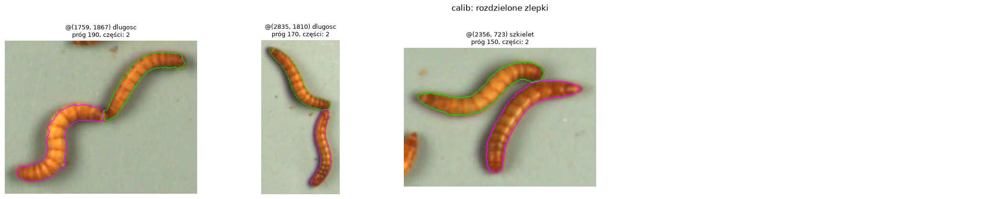

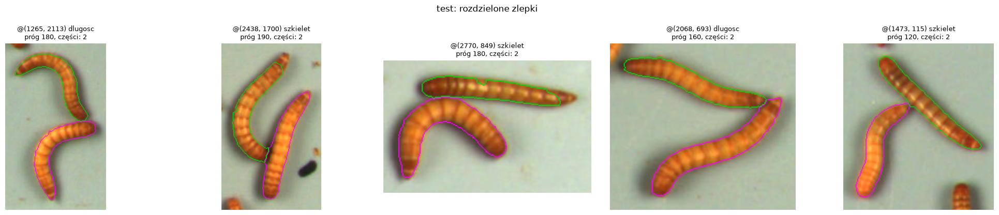

In [29]:
# Krok 6 na obu obrazach (parametry końcowe). Każda część zlepka ma inny kolor konturu.
rescued_calib, splits_calib = split_clumps(calib, dbg_calib)
rescued_test, splits_test = split_clumps(test, dbg_test)
for name, dbg, objs, rescued, splits in (('calib', dbg_calib, objs_calib, rescued_calib, splits_calib),
                                         ('test', dbg_test, objs_test, rescued_test, splits_test)):
    n_clumps = sum(c['reason'] in CLUMP_REASONS for c in dbg['candidates'])
    print(f'{name}: rozdzielone {len(splits)} z {n_clumps} zlepków, +{len(rescued)} larw ({len(objs)} -> {len(objs) + len(rescued)})')
    for s in splits:
        L = [p['length_px'] / dbg['ref_len'] for p in s['parts']]
        cover = sum(p['area'] for p in s['parts']) / s['clump']['area']
        print(f"  @{s['clump']['bbox'][:2]} ({s['clump']['reason']}): próg {s['thr']}, "
              f"L = {', '.join(f'{l:.2f}' for l in L)} x mediana, pokrycie {cover:.2f}")
show_splits(calib, splits_calib, cols=5, title='calib: rozdzielone zlepki')
show_splits(test, splits_test, cols=5, title='test: rozdzielone zlepki')

#### Eksperyment: parametry kroku 6 i zabezpieczenia

Zmieniam po jednym parametrze (pozostałe mają wartości końcowe) i liczę uratowane larwy. Obok: zlepki rozdzielone dodatkowo (+), utracone (−) albo rozdzielone przy innym progu (~) względem wersji końcowej. Na RoI nie ma zlepków, więc liczę na całych obrazach.

Pod tabelą: podziały, które przechodzą tylko bez jednego z zabezpieczeń (`k_min = 0` albo `min_cover = 0`), z długością części względem mediany (L) i pokryciem maski zlepka. Na nich widać, co zabezpieczenia odrzucają.

wariant           | calib                                    | test


końcowe           |  6 larw                                  | 10 larw 


open_k = 0        |  4 larw -@(2835, 1810) ~@(2356, 723): 150->160 | 10 larw ~@(1473, 115): 120->130 ~@(2068, 693): 160->170


open_k = 3        |  4 larw -@(2835, 1810) ~@(2356, 723): 150->160 | 10 larw 


open_k = 7        |  6 larw ~@(1759, 1867): 190->180 ~@(2356, 723): 150->140 |  8 larw -@(2438, 1700) ~@(1265, 2113): 180->170


grow = 0          |  2 larw -@(1759, 1867) -@(2835, 1810)    |  2 larw -@(1265, 2113) -@(2068, 693) -@(2438, 1700) -@(2770, 849)


... (7 outputs left out)

min_cover = 0     | 10 larw +@(1032, 172) +@(3005, 1814)     | 12 larw +@(1029, 273)


min_cover = 0.8   |  8 larw +@(3005, 1814)                   | 10 larw 


min_cover = 0.95  |  6 larw                                  | 10 larw 


thr_step = 5      |  6 larw ~@(1759, 1867): 190->185         | 10 larw ~@(1265, 2113): 180->175 ~@(2770, 849): 180->175
calib: pojedyncze larwy z kroków 1-5 krótsze niż 0.7 x mediana: 1 z 85 (0.59)
test: pojedyncze larwy z kroków 1-5 krótsze niż 0.7 x mediana: 1 z 91 (0.57)


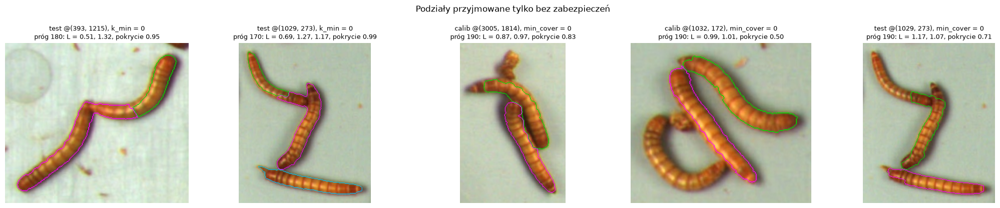

In [30]:
# Ablacja kroku 6: po jednym parametrze, reszta ma wartości końcowe
variants = [('końcowe', {}),
            ('open_k = 0', dict(open_k=0)), ('open_k = 3', dict(open_k=3)), ('open_k = 7', dict(open_k=7)),
            ('grow = 0', dict(grow=0)), ('grow = 3', dict(grow=3)), ('grow = 10', dict(grow=10)),
            ('min_part = 200', dict(min_part=200)), ('min_part = 1000', dict(min_part=1000)),
            ('k_min = 0', dict(k_min=0)), ('k_min = 0.6', dict(k_min=0.6)), ('k_min = 0.8', dict(k_min=0.8)),
            ('min_cover = 0', dict(min_cover=0)), ('min_cover = 0.8', dict(min_cover=0.8)),
            ('min_cover = 0.95', dict(min_cover=0.95)), ('thr_step = 5', dict(thr_step=5))]
images, infos = {'calib': calib, 'test': test}, {'calib': dbg_calib, 'test': dbg_test}
final = {name: {s['clump']['bbox']: s['thr'] for s in sp} for name, sp in (('calib', splits_calib), ('test', splits_test))}
guard_cases = []
print(f"{'wariant':17s} | {'calib':40s} | test")
for label, kw in variants:
    row = []
    for name in ('calib', 'test'):
        rescued, splits = split_clumps(images[name], infos[name], **kw)
        thr = {s['clump']['bbox']: s['thr'] for s in splits}
        diff = ([f'+@{b[:2]}' for b in sorted(thr.keys() - final[name].keys())] +
                [f'-@{b[:2]}' for b in sorted(final[name].keys() - thr.keys())] +
                [f'~@{b[:2]}: {final[name][b]}->{thr[b]}' for b in sorted(thr.keys() & final[name].keys()) if thr[b] != final[name][b]])
        row.append(f"{len(rescued):2d} larw {' '.join(diff)}")
        if label in ('k_min = 0', 'min_cover = 0'):
            guard_cases += [dict(s, img_name=name, label=label,
                                 L=[p['length_px'] / infos[name]['ref_len'] for p in s['parts']],
                                 cover=sum(p['area'] for p in s['parts']) / s['clump']['area'])
                            for s in splits if s['clump']['bbox'] not in final[name]]
    print(f'{label:17s} | {row[0]:40s} | {row[1]}')

# Uzasadnienie k_min: ile pojedynczych larw z kroków 1-5 jest krótszych niż 0.7 x mediana
for name in ('calib', 'test'):
    L = sorted(c['length_px'] / infos[name]['ref_len'] for c in infos[name]['candidates'] if c['reason'] is None)
    print(f"{name}: pojedyncze larwy z kroków 1-5 krótsze niż 0.7 x mediana: {sum(l < 0.7 for l in L)} z {len(L)} "
          f"({', '.join(f'{l:.2f}' for l in L if l < 0.7)})")

show_splits(images, guard_cases, cols=5, title='Podziały przyjmowane tylko bez zabezpieczeń', title_fn=lambda s: (
    f"{s['img_name']} @{s['clump']['bbox'][:2]}, {s['label']}\n"
    f"próg {s['thr']}: L = {', '.join(f'{l:.2f}' for l in s['L'])}, pokrycie {s['cover']:.2f}"))

**Wniosek (krok 6):**
* Krok 6 rozdziela 3 z 18 zlepków na `calib` i 5 z 23 na `test`, czyli +6 i +10 larw (85 → 91, 91 → 101). Wszystkie uratowane maski wyglądają na całe, pojedyncze larwy (galerie wyżej). Rozdzielają się pary, które stykają się końcami albo bokiem przez poświatę. Skrzyżowane larwy zostają odrzucone, bo przykryta larwa rozpada się na kawałki krótsze niż `k_min`.
* **Otwarcie (`open_k` = 5).** Bez otwarcia i przy 3×3 na `calib` nie rozdziela się para @(2835, 1810). Przy 7×7 na `test` ginie para @(2438, 1700).
* **Odbudowa (`grow` = 6 px).** Bez niej zostają tylko 2 + 2 larwy: części po wysokim progu są cieńsze i krótsze od larw, więc nie przechodzą filtra albo pokrycia. Przy 3 px ginie po jednym zlepku na obrazie, a 6 i 10 px dają ten sam wynik.
* **`min_part`** od 200 do 1000 px nie zmienia wyniku.
* **`k_min` = 0.7.** Bez niego na `test` przechodzą 2 złe podziały (galeria wyżej): kawałek larwy (0.51×) razem z sąsiadką, do której dokleił się fragment (1.32×), oraz obcięta larwa (0.69×) z sąsiadką, która zabrała jej koniec. Części poprawnych podziałów mają ≥ 0.80×, a wynik jest ten sam dla `k_min` od 0.7 do 0.8. Wśród pojedynczych larw z kroków 1–5 krótsza niż 0.7× jest tylko jedna na każdym obrazie, więc ten próg rzadko odrzuci prawdziwą larwę.
* **`min_cover` = 0.9.** Bez niego na `test` przechodzi zlepek @(1029, 273) przy progu 190: bledsza larwa znika, a jej koniec dokleja się do sąsiadki (pokrycie 0.71). Na `calib` przechodzi para @(3005, 1814) (0.83), w której górna larwa przykrywa koniec dolnej. Kosztem jest zlepek @(1032, 172) na `calib`: obie części są poprawne, ale znika trzecia larwa, która leży częściowo pod jedną z nich (pokrycie 0.50). Pokrycie nie odróżnia tych sytuacji, więc wolę stracić 2 dobre larwy niż przyjąć złą maskę. Poprawne podziały mają pokrycie ≥ 0.96, a wynik jest ten sam dla `min_cover` od 0.9 do 0.95.
* **Krok progu 5** zamiast 10 rozdziela te same zlepki, część przy progu niższym o 5. Zostawiam 10.
* Analiza instancji niżej korzysta z wyniku kroków 1–5. Uratowane larwy można do niej dołączyć (`objs_calib + rescued_calib`).

### Analiza instancji: długość, grubość, kształt

`analyze_objects` przyjmuje listę instancji z `detect_objects` i dla każdej maski liczy:

**Długość** (miara główna, zwalidowana poniżej):
1. szkielet (`skeletonize`) wygładzonej maski i jego **najdłuższa ścieżka**, czyli oś larwy bez bocznych gałązek;
2. **wygładzenie osi** filtrem Gaussa. Szkielet to schodki w 8-sąsiedztwie, a ich długość jest większa niż długość gładkiej krzywej;
3. **przedłużenie obu końców** wzdłuż stycznej aż do brzegu maski. Szkielet kończy się mniej więcej jeden promień przed czubkiem larwy, więc bez tej korekty długość jest zaniżona. Brzeg wyznaczam podpikselowo (maska interpolowana dwuliniowo, brzeg na poziomie 0.5).

**Grubość:** cięciwy prostopadłe do osi, mierzone tą samą podpikselową metodą. Wynik to mediana ze środkowych 60% długości, bo końce larwy są zwężone. Zapisuję też maksimum i cały profil grubości.

**Kształt I / C / S:** przebieg kąta stycznej wzdłuż osi, z pominięciem końcówek (po 10%, bo główka i ogon bywają lokalnie zagięte). Oś dzielę na zakręty, czyli odcinki o stałym znaku krzywizny, i liczę kąt skrętu każdego z nich:
* brak zakrętu ≥ 35° → **I**;
* co najmniej dwa znaczące zakręty w przeciwne strony → **S**;
* w przeciwnym razie → **C**.

Wszystkie wartości są w pikselach. Nie znamy skali obrazu (brak wzorca na zdjęciu), więc przeliczenie na mm wymagałoby kalibracji.

In [31]:
PAD = 2  # margines wokół maski, żeby brzeg obiektu nie leżał na brzegu tablicy


def polyline_length(p: np.ndarray) -> float:
    return float(np.linalg.norm(np.diff(p, axis=0), axis=1).sum()) if len(p) > 1 else 0.0


def resample_polyline(p: np.ndarray, step: float = 1.0) -> np.ndarray:
    """Równomierne próbkowanie łamanej co `step` px."""
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    s = np.arange(0, d[-1], step)
    if d[-1] - s[-1] > 1e-6:
        s = np.r_[s, d[-1]]
    return np.c_[np.interp(s, d, p[:, 0]), np.interp(s, d, p[:, 1])]


def rays_to_edge(maskf: np.ndarray, points: np.ndarray, dirs: np.ndarray, step: float = 0.25, max_t: float = 60.0):
    """Dla każdego punktu: odległość wzdłuż zadanego kierunku do brzegu maski.
    Maska jest interpolowana dwuliniowo, a brzeg to poziom 0.5 (w połowie między pikselem obiektu i tła),
    więc wynik jest podpikselowy. Liczone wektorowo dla wszystkich punktów naraz."""
    dirs = dirs / (np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-9)
    t = np.arange(step, max_t + step, step)
    q = points[:, None, :] + t[None, :, None] * dirs[:, None, :]
    vals = map_coordinates(maskf, q.reshape(-1, 2).T, order=1, mode='constant').reshape(len(points), len(t))
    outside = vals < 0.5
    first_out = np.where(outside.any(axis=1), outside.argmax(axis=1), len(t))
    return first_out * step


def classify_shape(centerline: np.ndarray, sigma: float = 6.0, trim: float = 0.1, lobe_deg: float = 35.0):
    """Klasyfikacja I / C / S na podstawie przebiegu kąta stycznej wzdłuż linii środkowej.
    Końcówki (`trim` długości z każdej strony) są pomijane, bo główka i ogon bywają lokalnie zagięte.
    Linię dzielę na zakręty (odcinki o stałym znaku krzywizny) i sumuję kąt skrętu w każdym:
      brak zakrętu >= lobe_deg -> I;  >= 2 znaczące zakręty o przeciwnych znakach -> S;  inaczej -> C."""
    p = np.c_[gaussian_filter1d(centerline[:, 0], sigma, mode='nearest'),
              gaussian_filter1d(centerline[:, 1], sigma, mode='nearest')]
    cut = int(trim * len(p))
    p = p[cut:len(p) - cut]
    if len(p) < 3:
        return 'I', dict(lobes=[], significant=[], theta=np.zeros(0))
    d = np.diff(p, axis=0)
    theta = np.unwrap(np.arctan2(d[:, 0], d[:, 1]))
    lobes, cur = [], 0.0
    for v in np.diff(theta):
        if cur == 0 or np.sign(v) == np.sign(cur):
            cur += v
        else:
            lobes.append(cur)
            cur = v
    lobes.append(cur)
    lobes = [float(np.degrees(l)) for l in lobes]
    significant = [l for l in lobes if abs(l) >= lobe_deg]
    if not significant:
        cls = 'I'
    elif any(np.sign(a) != np.sign(b) for a, b in zip(significant, significant[1:])):
        cls = 'S'
    else:
        cls = 'C'
    return cls, dict(lobes=lobes, significant=significant, theta=np.degrees(theta))


def analyze_instance(obj: dict, sigma: float = 3.0, k_dir: int = 8, mid=(0.2, 0.8), open_k: int = 7,
                     **shape_kw) -> dict:
    """Pomiar pojedynczej instancji na podstawie jej maski binarnej (obj['mask']).
      1. szkielet wygładzonej maski -> najdłuższa ścieżka (oś larwy, bez bocznych gałązek),
      2. wygładzenie osi filtrem Gaussa (usuwa schodki 8-sąsiedztwa, które zawyżają długość),
      3. przedłużenie obu końców wzdłuż stycznej aż do brzegu maski (szkielet kończy się ok. promień przed
         czubkiem larwy, co zaniża długość),
      4. grubość: cięciwy prostopadłe do osi; mediana ze środkowej części (`mid`), bo końce są zwężone,
      5. kształt I/C/S z przebiegu kąta stycznej (classify_shape)."""
    m = np.pad(obj['mask'], PAD).astype(np.uint8)
    maskf = m.astype(np.float32)
    smooth_mask = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    skel = skm.skeletonize(smooth_mask > 0)
    geo_len, path = skeleton_longest_path(skel)
    res = dict(length_naive=float(skel.sum()), length_geodesic=float(geo_len))
    if len(path) < 2 * k_dir + 2:
        res.update(length=np.nan, length_smooth=np.nan, width=np.nan, width_dt=np.nan, width_max=np.nan,
                   shape=None, straightness=np.nan)
        return res

    # 2. wygładzona oś, próbkowana co 1 px
    path = path.astype(np.float64)
    smooth = np.c_[gaussian_filter1d(path[:, 0], sigma, mode='nearest'),
                   gaussian_filter1d(path[:, 1], sigma, mode='nearest')]
    smooth = resample_polyline(smooth, 1.0)

    # 3. przedłużenie końców wzdłuż stycznej do brzegu maski
    k = min(k_dir, len(smooth) - 1)
    ends = np.array([smooth[0], smooth[-1]])
    dirs = np.array([smooth[0] - smooth[k], smooth[-1] - smooth[-1 - k]])
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    ext = rays_to_edge(maskf, ends, dirs)
    tips = ends + ext[:, None] * dirs
    length_smooth = polyline_length(smooth)
    length = length_smooth + float(ext.sum())

    # 4. grubość: cięciwy prostopadłe do osi
    tang = np.gradient(smooth, axis=0)
    tang /= np.linalg.norm(tang, axis=1, keepdims=True) + 1e-9
    normals = np.c_[-tang[:, 1], tang[:, 0]]
    w_plus, w_minus = rays_to_edge(maskf, smooth, normals), rays_to_edge(maskf, smooth, -normals)
    widths = w_plus + w_minus
    pos = (ext[0] + np.r_[0, np.cumsum(np.linalg.norm(np.diff(smooth, axis=0), axis=1))]) / length
    sel = (pos >= mid[0]) & (pos <= mid[1])
    if not sel.any():
        sel[:] = True
    # dla porównania: klasyczna grubość 2 x transformata odległości na osi
    dt = cv2.distanceTransform(m, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    widths_dt = 2 * map_coordinates(dt, smooth.T, order=1)

    # 5. kształt
    shape, shape_info = classify_shape(smooth, **shape_kw)

    off = np.array([PAD, PAD])
    res.update(
        length=length,
        length_smooth=length_smooth,
        width=float(np.median(widths[sel])),
        width_max=float(widths.max()),
        width_dt=float(np.median(widths_dt[sel])),
        shape=shape,
        straightness=float(np.linalg.norm(tips[1] - tips[0]) / length),
        lobes=shape_info['significant'],
        centerline=np.vstack([tips[0], smooth, tips[1]]) - off,
        _debug=dict(skeleton=skel[PAD:-PAD, PAD:-PAD], path=path - off, smooth=smooth - off, tips=tips - off,
                    ext=ext, normals=normals, w_plus=w_plus, w_minus=w_minus, widths=widths, pos=pos,
                    mid=mid, shape_info=shape_info),
    )
    return res


def analyze_objects(instances: List, **kwargs) -> List:
    """Analiza wszystkich instancji z detect_objects. Zwraca kopie słowników uzupełnione o:
    length [px], width [px] (mediana grubości w środkowej części), width_max, shape ('I'/'C'/'S'),
    straightness (cięciwa / długość), lobes (znaczące zakręty w stopniach), centerline (oś z końcami)."""
    return [{**obj, **analyze_instance(obj, **kwargs)} for obj in instances]

In [32]:
def show_analysis(a: dict, image: np.ndarray = None):
    """Podgląd analizy krok po kroku dla jednej instancji (wynik analyze_objects / analyze_instance)."""
    d, mask = a['_debug'], a['mask']
    n = 6 if image is not None else 5
    f, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.5))
    if image is not None:
        x, y, w, h = a['bbox']
        axes[0].imshow(image[y:y + h, x:x + w, ::-1])
        axes[0].set_title('RGB')
        axes[0].axis('off')
    a1, a2, a3, a4, a5 = axes[-5:]

    a1.imshow(mask, cmap='gray')
    sy, sx = np.nonzero(d['skeleton'])
    a1.plot(sx, sy, 'c.', ms=2, label='szkielet')
    a1.plot(d['path'][:, 1], d['path'][:, 0], 'r-', lw=1, label='najdłuższa ścieżka')
    a1.legend(fontsize=7, loc='lower right')
    a1.set_title(f"1. szkielet {a['length_naive']:.0f} px, ścieżka {a['length_geodesic']:.0f} px", fontsize=9)

    a2.imshow(mask, cmap='gray')
    a2.plot(d['smooth'][:, 1], d['smooth'][:, 0], 'r-', lw=1.5)
    for tip, end in zip(d['tips'], d['smooth'][[0, -1]]):
        a2.plot([end[1], tip[1]], [end[0], tip[0]], 'y-', lw=2.5)
    a2.plot(d['tips'][:, 1], d['tips'][:, 0], 'yo', ms=4)
    a2.set_title(f"2. wygładzona + końce (żółte): L = {a['length']:.1f} px", fontsize=9)

    a3.imshow(mask, cmap='gray')
    for i in range(0, len(d['smooth']), 6):
        p, nrm = d['smooth'][i], d['normals'][i]
        p1, p2 = p + d['w_plus'][i] * nrm, p - d['w_minus'][i] * nrm
        in_mid = d['mid'][0] <= d['pos'][i] <= d['mid'][1]
        a3.plot([p1[1], p2[1]], [p1[0], p2[0]], '-', color='lime' if in_mid else 'orange', lw=1)
    a3.set_title(f"3. cięciwy: grubość = {a['width']:.1f} px (max {a['width_max']:.1f})", fontsize=9)
    for ax in (a1, a2, a3):
        ax.axis('off')

    a4.plot(d['pos'], d['widths'], 'k-')
    a4.axvspan(*d['mid'], color='lime', alpha=0.2, label='zakres mediany')
    a4.axhline(a['width'], color='g', ls='--', label=f"mediana {a['width']:.1f} px")
    a4.set_xlabel('pozycja wzdłuż larwy (0 → 1)')
    a4.set_ylabel('grubość [px]')
    a4.set_title('4. profil grubości', fontsize=9)
    a4.legend(fontsize=7)

    si = d['shape_info']
    if len(si['theta']):
        a5.plot(si['theta'] - si['theta'][0], 'b-')
    a5.axhline(0, color='gray', lw=0.5)
    a5.set_xlabel('px wzdłuż linii (bez końcówek)')
    a5.set_ylabel('kąt stycznej względem początku [°]')
    a5.set_title(f"5. kształt {a['shape']}: zakręty {[round(l) for l in si['significant']]}°", fontsize=9)
    plt.tight_layout()

kształty  calib: {'S': 8, 'C': 63, 'I': 14}   test: {'C': 59, 'S': 9, 'I': 23}


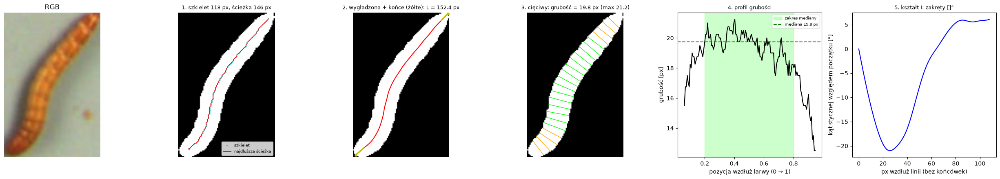

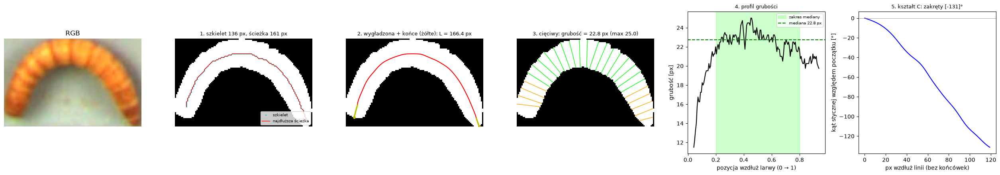

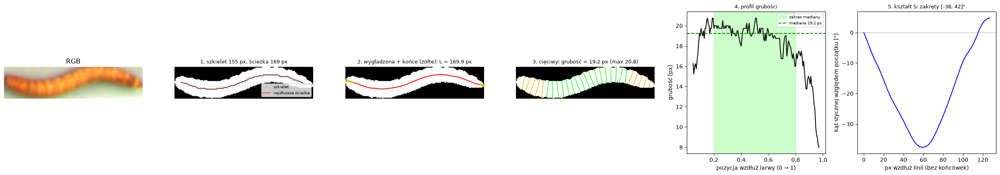

In [33]:
an_calib = analyze_objects(objs_calib)
an_test = analyze_objects(objs_test)
print('kształty  calib:', dict(Counter(a['shape'] for a in an_calib)), '  test:', dict(Counter(a['shape'] for a in an_test)))

# Analiza krok po kroku: po jednym przykładzie każdej klasy kształtu
for cls in 'ICS':
    show_analysis(next(a for a in an_calib if a['shape'] == cls), calib)

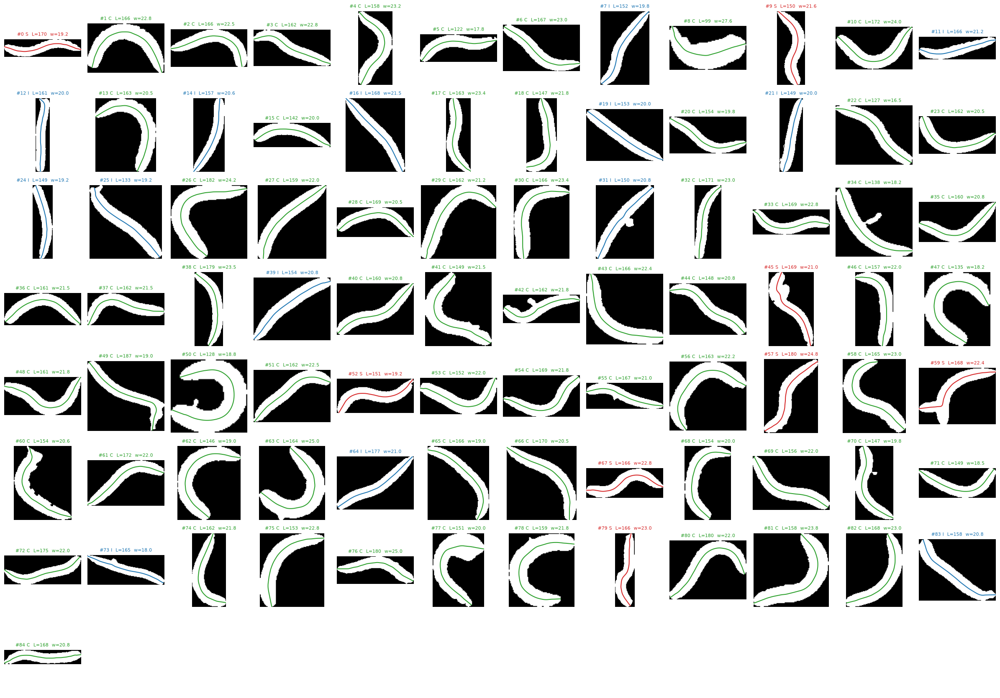

In [34]:
# Galeria wszystkich larw z calib: linia środkowa w kolorze klasy kształtu, w tytule długość i grubość.
# Pozwala szybko ocenić klasyfikację i wychwycić dziwne maski.
colors = {'I': 'tab:blue', 'C': 'tab:green', 'S': 'tab:red'}
cols = 12
rows = int(np.ceil(len(an_calib) / cols))
f, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.1 * rows))
for ax in axes.ravel():
    ax.axis('off')
for i, (ax, a) in enumerate(zip(axes.ravel(), an_calib)):
    ax.imshow(a['mask'], cmap='gray')
    ax.plot(a['centerline'][:, 1], a['centerline'][:, 0], '-', color=colors[a['shape']], lw=1.5)
    ax.set_title(f"#{i} {a['shape']}  L={a['length']:.0f}  w={a['width']:.1f}", fontsize=8, color=colors[a['shape']])
plt.tight_layout()

#### Eksperyment: siła erozji brzegu a pomiar

Erozja na kanale B (krok 4 detekcji) zdejmuje piksele mieszane z tłem; w kroku 4 widać, które. Nie wiadomo jednak, gdzie dokładnie leży „prawdziwy” brzeg larwy, a od tego zależy zmierzona grubość. Sprawdzam, jak `refine_delta` wpływa na liczbę wykrytych larw oraz mediany pola, grubości i długości. Mniejsza `delta` oznacza mocniejszą erozję.

bez erozji             n= 84   mediana: pole   3400 px, grubość 22.50 px, długość  162.9 px


delta=45               n= 84   mediana: pole   3343 px, grubość 22.25 px, długość  162.4 px


delta=30 (domyślnie)   n= 85   mediana: pole   3213 px, grubość 21.50 px, długość  161.6 px


delta=15               n= 83   mediana: pole   2837 px, grubość 19.00 px, długość  159.0 px


(np.float64(-0.5), np.float64(161.5), np.float64(91.5), np.float64(-0.5))

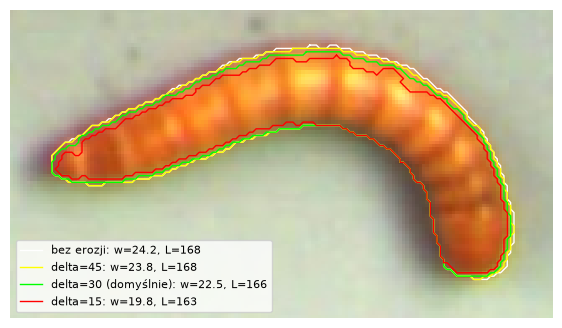

In [35]:
variants = [('bez erozji', dict(refine_iters=0)), ('delta=45', dict(refine_delta=45)),
            ('delta=30 (domyślnie)', dict(refine_delta=30)), ('delta=15', dict(refine_delta=15))]
variant_results = {}
for name, kw in variants:
    an = analyze_objects(detect_objects(calib, S_THR, **kw))
    variant_results[name] = an
    print(f"{name:22s} n={len(an):3d}   mediana: pole {np.median([a['area'] for a in an]):6.0f} px, "
          f"grubość {np.median([a['width'] for a in an]):5.2f} px, długość {np.median([a['length'] for a in an]):6.1f} px")

# ta sama larwa we wszystkich wariantach
ref = an_calib[2]
x, y, w, h = ref['bbox']
cx, cy, pad = x + w / 2, y + h / 2, 12
x0, y0 = max(x - pad, 0), max(y - pad, 0)
f, ax = plt.subplots(figsize=(7, 7))
ax.imshow(calib[y0:y + h + pad, x0:x + w + pad, ::-1])
for (name, an), col in zip(variant_results.items(), ['white', 'yellow', 'lime', 'red']):
    a = min(an, key=lambda a: (a['bbox'][0] + a['bbox'][2] / 2 - cx) ** 2 + (a['bbox'][1] + a['bbox'][3] / 2 - cy) ** 2)
    cnt = a['contour'][:, 0, :] - [x0, y0]
    ax.plot(np.r_[cnt[:, 0], cnt[0, 0]], np.r_[cnt[:, 1], cnt[0, 1]], '-', color=col, lw=1,
            label=f"{name}: w={a['width']:.1f}, L={a['length']:.0f}")
ax.legend(fontsize=8)
ax.axis('off')

**Wniosek:**
* Siła erozji zmienia medianę grubości o ok. 3.5 px: 22.5 px bez erozji, 19.0 px przy `delta=15`. Długość zmienia się dużo mniej, o ok. 3.9 px, czyli ok. 2% wobec ok. 15% dla grubości.
* Bez wzorca nie da się rozstrzygnąć, który brzeg jest „prawdziwy”. Wybrałem `delta=30`, który zdejmuje tylko wyraźnie jasne piksele mieszane z tłem i nie wcina się w ciało larwy, w przeciwieństwie do `delta=15`, który robi to zwłaszcza po stronie cienia.
* Liczba wykrytych larw prawie się nie zmienia (83–85), więc erozja wpływa na pomiar, a nie na detekcję.
* **Praktyczny wniosek:** grubość bezwzględna ma niepewność rzędu ±1–2 px wynikającą z definicji brzegu, ale porównania względne (między larwami lub partiami, przy tych samych parametrach) pozostają ważne.

#### Walidacja pomiaru na syntetycznych larwach

Do prawdziwych larw nie ma pomiaru referencyjnego, więc dokładność sprawdzam na **syntetycznych maskach o znanej długości i grubości**. Generuję 60 larw: po 20 kształtów I, C i S, z losową długością 120–200 px, grubością 17–24 px, obrotem i zwężonymi końcami (jak u prawdziwych larw). Porównuję kolejne warianty metody, żeby pokazać, co daje każdy krok.

DŁUGOŚĆ                         błąd śr.  odch. std  |błąd| wzgl.
liczba pikseli szkieletu         -24.12px     8.60px       14.80 %
najdłuższa ścieżka szkieletu      -3.55px     3.75px        2.77 %
wygładzona linia środkowa        -15.12px     2.68px        9.39 %
wygładzona + przedłużone końce    -1.04px     1.09px        0.77 %

GRUBOŚĆ                       
2 x transformata odległości       -0.31px     0.29px        1.68 %
cięciwy prostopadłe               -0.09px     0.16px        0.67 %

KSZTAŁT (prawdziwy -> przewidziany): {('I', 'I'): 20, ('C', 'C'): 20, ('S', 'S'): 20}


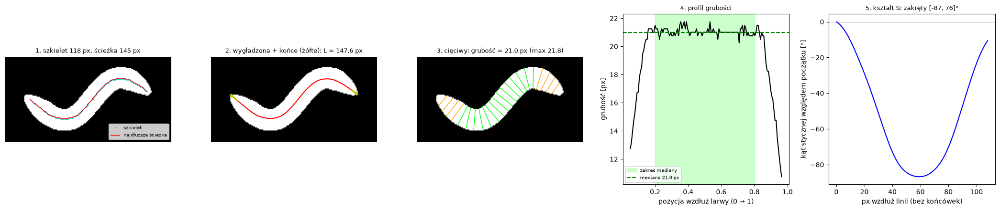

In [36]:
def make_synthetic_larva(kind: str, length: float, width: float, angle: float, taper: float = 0.15, r_min: float = 1.0):
    """Syntetyczna maska larwy o znanej linii środkowej: I (prosta), C (łuk 180°), S (sinusoida).
    Promień zwęża się na końcach (`taper` = część długości). Zwraca (maska, długość GT, grubość GT).
    GT liczę w zasięgu pikseli: cv2.circle zapala piksele o środku w odległości <= r, więc brzeg maski
    leży 0.5 px dalej, czyli figura jest o 1 px dłuższa i o 1 px grubsza niż wynika z parametrów (sprawdzone)."""
    s = np.linspace(0, length, int(length * 4))
    if kind == 'I':
        x, y = s, np.zeros_like(s)
    elif kind == 'C':
        R = length / np.pi
        x, y = R * np.sin(s / R), R * (1 - np.cos(s / R))
    else:  # S: sinusoida sparametryzowana długością łuku
        xx = np.linspace(0, length, 20000)
        yy = 0.12 * length * np.sin(2 * np.pi * xx / (0.75 * length))
        arc = np.r_[0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        x, y = np.interp(s, arc, xx), np.interp(s, arc, yy)
    c, sn = np.cos(angle), np.sin(angle)
    X, Y = c * x - sn * y, sn * x + c * y
    X, Y = X - X.min() + width, Y - Y.min() + width
    mask = np.zeros((int(Y.max() + width) + 2, int(X.max() + width) + 2), np.uint8)
    u = s / length
    r = np.maximum(width / 2 * np.clip(np.minimum(u, 1 - u) / taper, 0, 1) ** 0.5, r_min)
    for xi, yi, ri in zip(X, Y, r):
        cv2.circle(mask, (int(round(xi * 8)), int(round(yi * 8))), int(round(ri * 8)), 1, -1, shift=3)
    return mask, length + 2 * r_min + 1, width + 1


rng = np.random.default_rng(0)
synth = []
for kind in 'ICS':
    for _ in range(20):
        L, W = rng.uniform(120, 200), rng.uniform(17, 24)
        mask, gt_len, gt_w = make_synthetic_larva(kind, L, W, rng.uniform(0, np.pi))
        synth.append(dict(kind=kind, gt_len=gt_len, gt_w=gt_w, mask=mask, **analyze_instance({'mask': mask})))

gt_len = np.array([r['gt_len'] for r in synth])
gt_w = np.array([r['gt_w'] for r in synth])
print(f"{'DŁUGOŚĆ':30s} {'błąd śr.':>9s} {'odch. std':>10s} {'|błąd| wzgl.':>13s}")
for key, name in [('length_naive', 'liczba pikseli szkieletu'), ('length_geodesic', 'najdłuższa ścieżka szkieletu'),
                  ('length_smooth', 'wygładzona linia środkowa'), ('length', 'wygładzona + przedłużone końce')]:
    err = np.array([r[key] for r in synth]) - gt_len
    print(f'{name:30s} {err.mean():+8.2f}px {err.std():8.2f}px {100 * np.mean(np.abs(err) / gt_len):11.2f} %')
print(f"\n{'GRUBOŚĆ':30s}")
for key, name in [('width_dt', '2 x transformata odległości'), ('width', 'cięciwy prostopadłe')]:
    err = np.array([r[key] for r in synth]) - gt_w
    print(f'{name:30s} {err.mean():+8.2f}px {err.std():8.2f}px {100 * np.mean(np.abs(err) / gt_w):11.2f} %')
print('\nKSZTAŁT (prawdziwy -> przewidziany):', dict(Counter((r['kind'], r['shape']) for r in synth)))

# podgląd jednego syntetycznego przykładu S
show_analysis(next(r for r in synth if r['kind'] == 'S'))

I: n= 37, mediana długości  156.7 px, IQR 150-166
C: n=122, mediana długości  160.1 px, IQR 151-166
S: n= 17, mediana długości  165.7 px, IQR 151-170


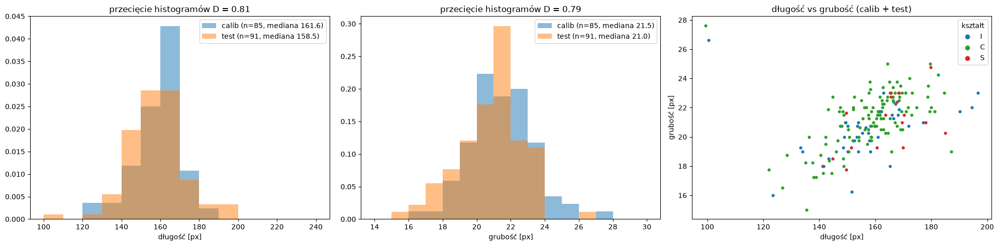

In [37]:
# Statystyki populacji: calib vs test.
# Zdjęcia zrobiono w odstępie ~1 min, więc to najpewniej te same larwy w innych pozach (jak seria zdjęć
# w artykule). Rozkłady powinny się więc pokrywać - to test powtarzalności pomiaru niezależnie od pozy.
# Miara zgodności: przecięcie histogramów D = sum(min(h1, h2)) - ta sama, której używa artykuł (wzór 2).
def hist_intersection(a, b, bins) -> float:
    ha, _ = np.histogram(a, bins)
    hb, _ = np.histogram(b, bins)
    return float(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())

f, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, key, bins, label in [(axes[0], 'length', np.arange(100, 241, 10), 'długość [px]'),
                             (axes[1], 'width', np.arange(14, 30.5, 1), 'grubość [px]')]:
    vc, vt = [a[key] for a in an_calib], [a[key] for a in an_test]
    ax.hist(vc, bins, alpha=0.5, density=True, label=f'calib (n={len(vc)}, mediana {np.median(vc):.1f})')
    ax.hist(vt, bins, alpha=0.5, density=True, label=f'test (n={len(vt)}, mediana {np.median(vt):.1f})')
    ax.set_xlabel(label)
    ax.set_title(f'przecięcie histogramów D = {hist_intersection(vc, vt, bins):.2f}')
    ax.legend()
colors = {'I': 'tab:blue', 'C': 'tab:green', 'S': 'tab:red'}
for a in an_calib + an_test:
    axes[2].scatter(a['length'], a['width'], c=colors[a['shape']], s=12)
for cls, col in colors.items():
    axes[2].scatter([], [], c=col, label=cls)
axes[2].set_xlabel('długość [px]'); axes[2].set_ylabel('grubość [px]'); axes[2].legend(title='kształt')
axes[2].set_title('długość vs grubość (calib + test)')
plt.tight_layout()

# Czy długość zależy od pozy? Jeśli pomiar jest dobry, mediany w klasach I/C/S powinny być zbliżone.
for cls in 'ICS':
    v = [a['length'] for a in an_calib + an_test if a['shape'] == cls]
    print(f'{cls}: n={len(v):3d}, mediana długości {np.median(v):6.1f} px, IQR {np.percentile(v, 25):.0f}-{np.percentile(v, 75):.0f}')

#### Wnioski z analizy

**Długość (miara główna).** Walidacja na 60 syntetycznych larwach:

| metoda | błąd średni | odch. std | średni \|błąd\| względny |
|---|---|---|---|
| liczba pikseli szkieletu (naiwnie) | −24.1 px | 8.6 px | 14.8 % |
| najdłuższa ścieżka szkieletu | −3.6 px | 3.8 px | 2.8 % |
| wygładzona linia środkowa | −15.1 px | 2.7 px | 9.4 % |
| **wygładzona + przedłużone końce** | **−1.0 px** | **1.1 px** | **0.8 %** |

* Naiwne liczenie pikseli szkieletu zaniża długość o ok. 15%, bo krok ukośny liczy się jako 1 zamiast √2, a szkielet kończy się przed czubkami.
* Najdłuższa ścieżka daje mały błąd średni, ale tylko dzięki temu, że dwa błędy się znoszą: schodki zawyżają długość, a skrócone końce ją zaniżają. Rozrzut pozostaje duży (σ = 3.8 px).
* Samo wygładzenie usuwa schodki i odsłania prawdziwy niedomiar na końcach (≈ −15 px, czyli ok. jeden promień z każdej strony).
* Przedłużenie końców ten niedomiar usuwa. Zostaje ok. −1 px, bo przy zwężonym czubku promień trafia w brzeg odrobinę wcześniej.

Każdy krok ma więc uzasadnienie, a końcowa metoda jest prawie nieobciążona i ma rozrzut ok. 1 px.

**Grubość.** Cięciwy prostopadłe do osi: −0.09 ± 0.16 px. Klasyczne 2 × transformata odległości: −0.31 ± 0.29 px. Na prawdziwych danych grubość rośnie razem z długością (wykres rozrzutu), co ma sens biologicznie, bo większe larwy są grubsze.

**Kształt.** Na syntetykach 60/60 trafień. Na prawdziwych larwach przeważają C (≈ 2/3), potem I i S. Granica między łagodnym C a I oraz między C a S zależy od progu `lobe_deg`. Nie ma tu „prawdziwej” etykiety, więc warto ocenić galerię wzrokowo.

**Powtarzalność na prawdziwych danych.** Dwa zdjęcia zrobione w odstępie ok. 1 min dają zgodne rozkłady: przecięcie histogramów D ≈ 0.81 dla długości i ≈ 0.79 dla grubości, mediany 161.6 i 158.5 px. Mediana długości jest podobna dla larw I, C i S (≈ 157–166 px). To sugeruje, że pomiar nie zależy mocno od pozy: wygięta larwa nie wychodzi krótsza.

**Ograniczenia:**
* Pomiar jest dokładny względem **maski**, więc błędy segmentacji (erozja brzegu na kanale B, przyklejone okruchy) przechodzą wprost na grubość i, w mniejszym stopniu, na długość.
* Mocno zwinięte larwy (prawie pierścień, końce blisko siebie) mają niepewne końce szkieletu.
* Brak skali, więc wyniki są w pikselach.